# Прототип книжного рекомендательного сервиса (Goodbooks-10k)

План работы:
1. Знакомство с данными и EDA
2. Базовые и контентные модели (Popularity, TF-IDF)
3. Item-Based Collaborative Filtering
4. Матричные разложения (SVD)
5. Оценка и сравнение моделей (Precision@K, Recall@K, nDCG@K)
6. Гибридизация и выводы

## Этап 1. Знакомство с данными и EDA

In [96]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

DATA_DIR = "goodsbooks-10k"

### 1.1 Загрузка данных

In [97]:
ratings   = pd.read_csv(f"{DATA_DIR}/ratings.csv")
books     = pd.read_csv(f"{DATA_DIR}/books.csv")
tags      = pd.read_csv(f"{DATA_DIR}/tags.csv")
book_tags = pd.read_csv(f"{DATA_DIR}/book_tags.csv")

for name, df in [("ratings", ratings), ("books", books), ("tags", tags), ("book_tags", book_tags)]:
    print(f"{name:10s} {df.shape}")

ratings    (981756, 3)
books      (10000, 23)
tags       (34252, 2)
book_tags  (999912, 3)


In [98]:
ratings.head()

,book_id,user_id,rating
0,1,314,5
1,1,439,3
2,1,588,5
3,1,1169,4
4,1,1185,4


In [99]:
books[['id', 'book_id', 'authors', 'original_title', 'title', 'average_rating', 'ratings_count']].head()

,id,book_id,authors,original_title,title,average_rating,ratings_count
0,1,2767052,Suzanne Collins,The Hunger Games,"The Hunger Games (The Hunger Games, #1)",4.34,4780653
1,2,3,"J.K. Rowling, Mary GrandPré",Harry Potter and the Philosopher's Stone,Harry Potter and the Sorcerer's Stone (Harry P...,4.44,4602479
2,3,41865,Stephenie Meyer,Twilight,"Twilight (Twilight, #1)",3.57,3866839
3,4,2657,Harper Lee,To Kill a Mockingbird,To Kill a Mockingbird,4.25,3198671
4,5,4671,F. Scott Fitzgerald,The Great Gatsby,The Great Gatsby,3.89,2683664


In [100]:
book_tags.merge(tags, on='tag_id').head()

,goodreads_book_id,tag_id,count,tag_name
0,1,30574,167697,to-read
1,1,11305,37174,fantasy
2,1,11557,34173,favorites
3,1,8717,12986,currently-reading
4,1,33114,12716,young-adult


**Важно про идентификаторы книг.** В датасете два разных ID:
- `books.id` (от 1 до 10000) — внутренний ID, его используют `ratings.csv` и `to_read.csv` (колонка `book_id`);
- `books.book_id` (он же `goodreads_book_id`) — ID на сайте Goodreads, его используют `book_tags.csv`.

Если соединить таблицы не по тем ключам, теги «приклеятся» к чужим книгам. Дальше везде считаем
основным ID `books.id`, а для тегов делаем маппинг `goodreads_book_id → id`.

### 1.2 Качество данных: пропуски и дубликаты

In [101]:
print("Пропуски в ratings:", ratings.isna().sum().sum())
print("Пропуски в books (топ колонок):")
print(books.isna().sum().loc[lambda s: s > 0].sort_values(ascending=False))

dups = ratings.duplicated(subset=["user_id", "book_id"]).sum()
print(f"\nДубликатов пар (user, book) в ratings: {dups}")

Пропуски в ratings: 0
Пропуски в books (топ колонок):
language_code                1084
isbn                          700
isbn13                        585
original_title                585
original_publication_year      21
dtype: int64

Дубликатов пар (user, book) в ratings: 2278


Дубликаты (один пользователь оценил одну книгу дважды) удаляем, оставляя последнюю оценку.
Пустой `original_title` заменим на `title`: он понадобится в контентной модели.

In [102]:
ratings = ratings.drop_duplicates(subset=["user_id", "book_id"], keep="last").reset_index(drop=True)
books["original_title"] = books["original_title"].fillna(books["title"])

n_users = ratings["user_id"].nunique()
n_books = ratings["book_id"].nunique()
print(f"Оценок: {len(ratings):,}  Пользователей: {n_users:,}  Книг: {n_books:,}")

Оценок: 979,478  Пользователей: 53,424  Книг: 10,000


### 1.3 Распределение оценок

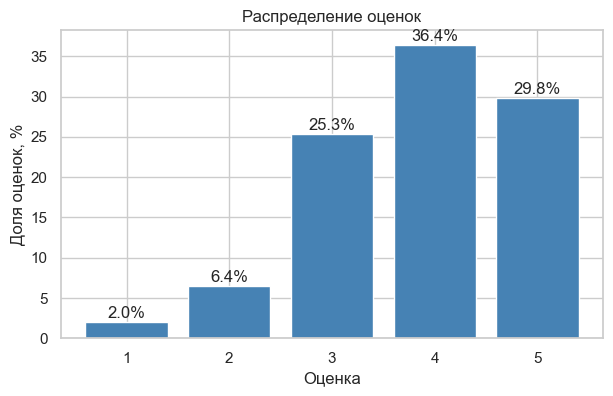

Средняя оценка: 3.86, медиана: 4
Доля оценок >= 4: 66.2%


In [103]:
rating_share = ratings["rating"].value_counts(normalize=True).sort_index()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(rating_share.index, rating_share.values * 100, color="steelblue")
for x, y in zip(rating_share.index, rating_share.values * 100):
    ax.text(x, y + 0.5, f"{y:.1f}%", ha="center")
ax.set_xlabel("Оценка"); ax.set_ylabel("Доля оценок, %")
ax.set_title("Распределение оценок")
plt.show()

print(f"Средняя оценка: {ratings['rating'].mean():.2f}, медиана: {ratings['rating'].median():.0f}")
print(f"Доля оценок >= 4: {(ratings['rating'] >= 4).mean():.1%}")

**Вывод.** Распределение сильно смещено к высоким оценкам: около 2/3 оценок равны 4 или 5,
а единиц всего около 2%. Люди в основном читают и оценивают то, что им заранее понравилось
(selection bias). Отсюда следствия:
- порог «релевантности» `rating >= 4` отсекает примерно треть оценок, что разумно;
- модель, которая всегда предсказывает примерно 3.9, уже даёт неплохой RMSE, поэтому RMSE стоит сравнивать с таким бейзлайном.

### 1.4 Активность пользователей

In [104]:
user_counts = ratings.groupby("user_id").size()
print(user_counts.describe().round(1))

count    53424.0
mean        18.3
std         26.2
min          1.0
25%          3.0
50%          8.0
75%         22.0
max        200.0
dtype: float64


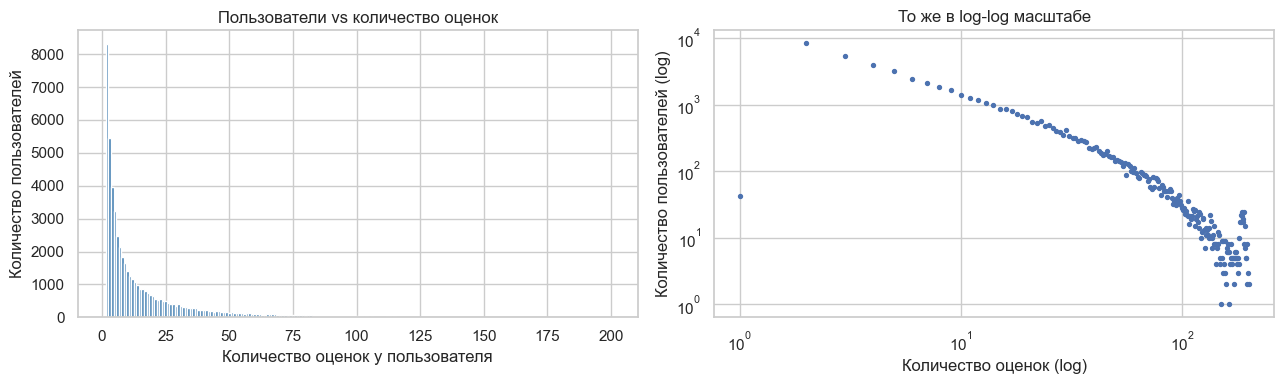

In [105]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Сколько пользователей поставили ровно k оценок
dist = user_counts.value_counts().sort_index()
axes[0].bar(dist.index, dist.values, width=1.0, color="steelblue")
axes[0].set_xlabel("Количество оценок у пользователя")
axes[0].set_ylabel("Количество пользователей")
axes[0].set_title("Пользователи vs количество оценок")

# Та же зависимость в log-log масштабе
axes[1].scatter(dist.index, dist.values, s=8)
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("Количество оценок (log)"); axes[1].set_ylabel("Количество пользователей (log)")
axes[1].set_title("То же в log-log масштабе")
plt.tight_layout(); plt.show()

In [106]:
bins   = [0, 4, 9, 49, 99, user_counts.max()]
labels = ["2-4 (холодные)", "5-9", "10-49", "50-99", "100+ (активные)"]
groups = pd.cut(user_counts, bins=bins, labels=labels)

summary = pd.DataFrame({
    "пользователей": groups.value_counts().reindex(labels),
    "доля пользователей": groups.value_counts(normalize=True).reindex(labels).round(3),
    "доля всех оценок": user_counts.groupby(groups, observed=False).sum().reindex(labels) / len(ratings),
}).round(3)
summary

,пользователей,доля пользователей,доля всех оценок
2-4 (холодные),17765,0.333,0.050
5-9,11285,0.211,0.077
10-49,19466,0.364,0.445
50-99,3714,0.070,0.259
100+ (активные),1194,0.022,0.169


**Вывод.** Типичный пользователь поставил всего несколько оценок (медиана около 8), примерно у трети
пользователей их меньше 5. Это **проблема холодного старта**: для таких людей коллаборативные
методы почти ничего не знают, и им разумно показывать популярные или контентные рекомендации.
Небольшая группа активных пользователей (100+ оценок, максимум 200) даёт заметную долю всех оценок.

### 1.5 Популярность книг и «длинный хвост»

In [107]:
book_counts = ratings.groupby("book_id").size()
print("Оценок на книгу в ratings.csv:")
print(book_counts.describe().round(1))

Оценок на книгу в ratings.csv:
count    10000.0
mean        97.9
std          5.8
min          8.0
25%         99.0
50%        100.0
75%        100.0
max        100.0
dtype: float64


Внутри `ratings.csv` у почти всех книг около 100 оценок: авторы датасета **ограничили выборку**
(не больше примерно 100 оценок на книгу). Поэтому настоящий «длинный хвост» здесь не виден.
Реальную популярность книг на Goodreads показывает колонка `books.ratings_count`, по ней и строим график.

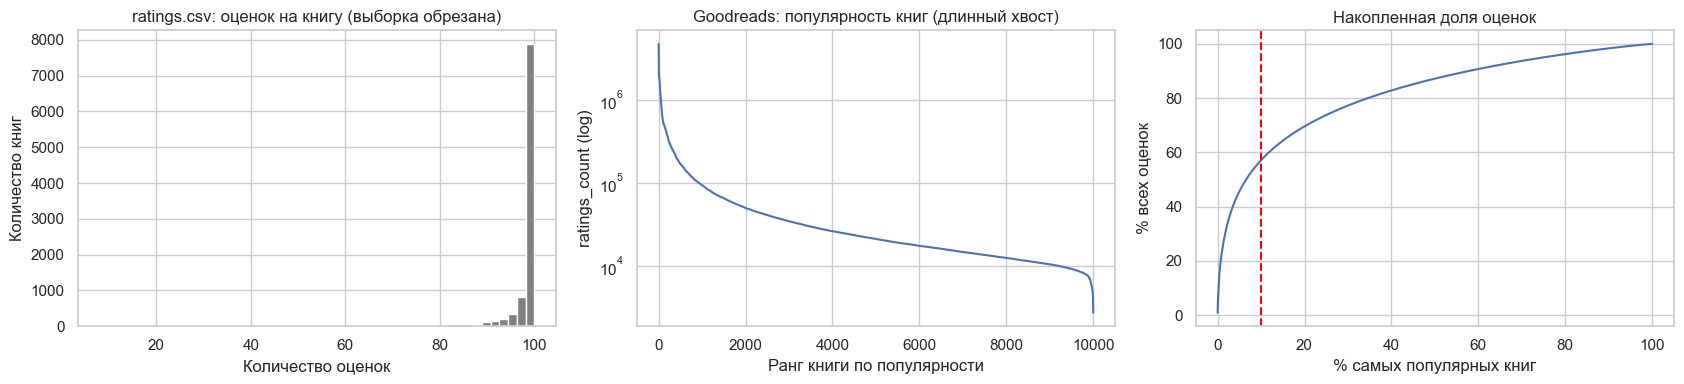

Топ-1% книг собирают 23.4% всех оценок Goodreads
Топ-10% книг собирают 57.1% всех оценок Goodreads


In [108]:
pop = books.sort_values("ratings_count", ascending=False)["ratings_count"].reset_index(drop=True)
cum_share = pop.cumsum() / pop.sum()

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

axes[0].hist(book_counts, bins=50, color="gray")
axes[0].set_title("ratings.csv: оценок на книгу (выборка обрезана)")
axes[0].set_xlabel("Количество оценок"); axes[0].set_ylabel("Количество книг")

axes[1].plot(pop.index + 1, pop.values)
axes[1].set_yscale("log")
axes[1].set_title("Goodreads: популярность книг (длинный хвост)")
axes[1].set_xlabel("Ранг книги по популярности"); axes[1].set_ylabel("ratings_count (log)")

axes[2].plot(np.arange(1, len(pop) + 1) / len(pop) * 100, cum_share.values * 100)
axes[2].axvline(10, ls="--", c="red")
axes[2].set_title("Накопленная доля оценок")
axes[2].set_xlabel("% самых популярных книг"); axes[2].set_ylabel("% всех оценок")
plt.tight_layout(); plt.show()

print(f"Топ-1% книг собирают {cum_share.iloc[len(pop)//100 - 1]:.1%} всех оценок Goodreads")
print(f"Топ-10% книг собирают {cum_share.iloc[len(pop)//10 - 1]:.1%} всех оценок Goodreads")

In [109]:
books.sort_values("ratings_count", ascending=False)[["id", "title", "authors", "ratings_count", "average_rating"]].head(10)

,id,title,authors,ratings_count,average_rating
0,1,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,4780653,4.34
1,2,Harry Potter and the Sorcerer's Stone (Harry P...,"J.K. Rowling, Mary GrandPré",4602479,4.44
2,3,"Twilight (Twilight, #1)",Stephenie Meyer,3866839,3.57
3,4,To Kill a Mockingbird,Harper Lee,3198671,4.25
4,5,The Great Gatsby,F. Scott Fitzgerald,2683664,3.89
5,6,The Fault in Our Stars,John Green,2346404,4.26
6,7,The Hobbit,J.R.R. Tolkien,2071616,4.25
7,8,The Catcher in the Rye,J.D. Salinger,2044241,3.79
9,10,Pride and Prejudice,Jane Austen,2035490,4.24
8,9,"Angels & Demons (Robert Langdon, #1)",Dan Brown,2001311,3.85


**Вывод.** Популярность распределена очень неравномерно: небольшая доля бестселлеров
(Гарри Поттер, Голодные игры, Сумерки…) собирает непропорционально много оценок, а у большинства
книг их на порядки меньше. Это **смещение популярности (popularity bias)**: модели склонны
рекомендовать одни и те же хиты, а книги из хвоста почти не попадают в выдачу.

### 1.6 Самые частые теги

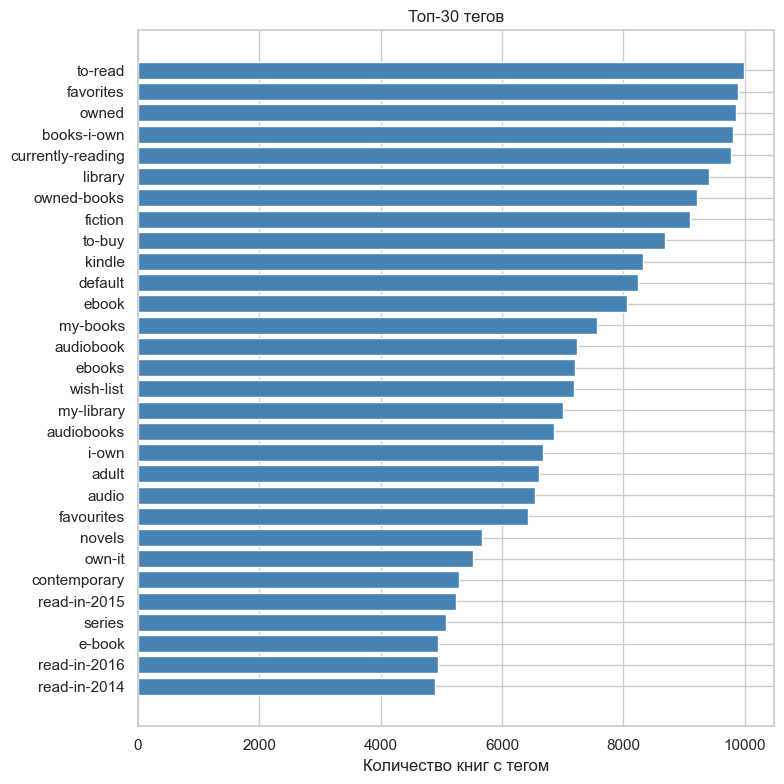

In [110]:
# Маппинг goodreads_book_id -> books.id и названия тегов
bt = (book_tags
      .merge(books[["id", "book_id"]], left_on="goodreads_book_id", right_on="book_id")
      .merge(tags, on="tag_id")
      [["id", "tag_name", "count"]]
      .rename(columns={"id": "book_id"}))

# count < 0 встречается в данных как артефакт, отбрасываем такие строки
bt = bt[bt["count"] > 0]

# Частота тега = у скольких книг он встречается (а не сумма count, иначе доминируют бестселлеры)
top_tags = bt.groupby("tag_name")["book_id"].nunique().sort_values(ascending=False).head(30)

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(top_tags.index[::-1], top_tags.values[::-1], color="steelblue")
ax.set_xlabel("Количество книг с тегом")
ax.set_title("Топ-30 тегов")
plt.tight_layout(); plt.show()

**Вывод.** Самые частые теги служебные: `to-read`, `favorites`, `currently-reading`, `owned`,
`books-i-own`… Они описывают отношение пользователя к книге, а не её содержание, поэтому
для контентной модели почти бесполезны. Жанровые теги (`fiction`, `fantasy`, `romance`, `classics`…)
содержательны. На этапе 2 это учтём: TF-IDF сам понизит вес слишком частых тегов (у них низкий IDF),
плюс можно явно убрать стоп-теги.

### 1.7 Разреженность матрицы взаимодействий

In [111]:
sparsity = 1 - len(ratings) / (n_users * n_books)
print(f"Размер матрицы user x book: {n_users:,} x {n_books:,} = {n_users * n_books:,} ячеек")
print(f"Заполнено: {len(ratings):,} ({1 - sparsity:.3%})")
print(f"Разреженность: {sparsity:.3%}")

Размер матрицы user x book: 53,424 x 10,000 = 534,240,000 ячеек
Заполнено: 979,478 (0.183%)
Разреженность: 99.817%


### Итоги EDA: основные проблемы данных

1. **Разреженность.** Заполнено меньше 0.2% матрицы user × book. Большинство пар пользователей и книг
   не имеют общих оценок, поэтому оценки сходства в CF шумные. Хранить матрицу нужно в разреженном
   формате (`scipy.sparse`).
2. **Смещение популярности.** Небольшая доля бестселлеров собирает основную массу оценок на Goodreads.
   Рекомендации рискуют свестись к «всем Гарри Поттера».
3. **Холодный старт пользователей.** Примерно у трети пользователей меньше 5 оценок.
4. **Смещение оценок вверх.** Около 2/3 оценок равны 4–5. Явные оценки слабо различают «понравилось»
   и «очень понравилось», поэтому полезно рассматривать и неявный фидбек (rating ≥ 4 → 1).
5. **Особенности выборки.** В `ratings.csv` около 100 оценок на книгу (выборка обрезана), а в
   `book_tags` много служебных тегов. Это нужно учитывать при интерпретации результатов.

## Этап 2. Базовые и контентные модели

### 2.1 Неперсонализированная модель: популярные книги

Идея: всем пользователям показываем одни и те же «лучшие» книги. Это самый простой бейзлайн,
и он же спасает при холодном старте, когда о пользователе ничего не известно.

**Почему нельзя просто отсортировать по средней оценке?** У книги с одной оценкой «5» среднее
равно 5.0, и она окажется выше «Гарри Поттера» со средним 4.4 по сотне оценок. Средняя по
маленькой выборке ненадёжна, поэтому вводим **порог минимального числа оценок** `min_ratings`.

Функции принимают таблицу оценок аргументом: на этапе 5 мы будем «обучать» модель только на
обучающей выборке.

In [112]:
book_titles = books.set_index("id")[["title", "authors"]]

def popularity_table(ratings_df, min_ratings=50):
    """Средний рейтинг и число оценок по книгам, только книги с count >= min_ratings."""
    stats = ratings_df.groupby("book_id")["rating"].agg(mean_rating="mean", n_ratings="count")
    stats = stats[stats["n_ratings"] >= min_ratings]
    return stats.sort_values(["mean_rating", "n_ratings"], ascending=False)


def get_popular_books(ratings_df, N=10, min_ratings=50, exclude=None):
    """Top-N книг по среднему рейтингу с порогом; exclude - книги, которые уже прочитаны."""
    table = popularity_table(ratings_df, min_ratings)
    if exclude is not None:
        table = table[~table.index.isin(exclude)]
    return table.head(N).join(book_titles)


get_popular_books(ratings, N=10, min_ratings=50)

,mean_rating,n_ratings,title,authors
book_id,,,,
7947,4.816092,87,ESV Study Bible,"Anonymous, Lane T. Dennis, Wayne A. Grudem"
5207,4.777778,99,The Days Are Just Packed: A Calvin and Hobbes ...,Bill Watterson
6920,4.777778,99,The Indispensable Calvin and Hobbes,Bill Watterson
9566,4.777778,99,Attack of the Deranged Mutant Killer Monster S...,Bill Watterson
3275,4.770000,100,"Harry Potter Boxed Set, Books 1-5 (Harry Potte...","J.K. Rowling, Mary GrandPré"
6361,4.770000,100,There's Treasure Everywhere: A Calvin and Hobb...,Bill Watterson
4483,4.750000,100,It's a Magical World: A Calvin and Hobbes Coll...,Bill Watterson
5580,4.750000,100,The Calvin and Hobbes Lazy Sunday Book,Bill Watterson
6590,4.750000,100,The Authoritative Calvin and Hobbes: A Calvin ...,Bill Watterson


**Что видно.** Наверху оказались не мировые бестселлеры, а нишевые книги: сборники комиксов
Calvin and Hobbes, ESV Study Bible, подарочные издания Гарри Поттера. Их оценивают в основном
преданные фанаты, поэтому среднее получается очень высоким.

Порог здесь почти не помогает: в нашем `ratings.csv` у всех книг около 100 оценок (см. EDA),
и порог 50 отсекает лишь единицы. Посмотрим, как меняется число книг при разных порогах:

In [113]:
book_n = ratings.groupby("book_id").size()
for t in [10, 50, 90, 100]:
    print(f"min_ratings={t:3d}: осталось книг {(book_n >= t).sum():,}")

min_ratings= 10: осталось книг 9,999
min_ratings= 50: осталось книг 9,990
min_ratings= 90: осталось книг 9,431
min_ratings=100: осталось книг 6,248


#### Улучшение: взвешенный (байесовский) рейтинг

Более аккуратный способ: не отсекать книги жёстко, а «притягивать» среднее книги к общему
среднему `C` тем сильнее, чем меньше у неё оценок. Это формула, которую использует IMDb:

$$WR = \frac{v}{v+m}\cdot R + \frac{m}{v+m}\cdot C$$

где `R` — средний рейтинг книги, `v` — число её оценок, `C` — средний рейтинг по всем книгам,
`m` — «доверительный» порог (например, 90-й перцентиль числа оценок). Книга с малым числом
оценок получает рейтинг, близкий к `C`, а книга с большим — близкий к своему `R`.

In [114]:
def weighted_popularity_table(ratings_df, m_quantile=0.9):
    stats = ratings_df.groupby("book_id")["rating"].agg(R="mean", v="count")
    C = ratings_df["rating"].mean()
    m = stats["v"].quantile(m_quantile)
    stats["weighted_rating"] = stats["v"] / (stats["v"] + m) * stats["R"] + m / (stats["v"] + m) * C
    return stats.sort_values("weighted_rating", ascending=False)


weighted_popularity_table(ratings).head(10).join(book_titles)

,R,v,weighted_rating,title,authors
book_id,,,,,
5207,4.777778,99,4.314618,The Days Are Just Packed: A Calvin and Hobbes ...,Bill Watterson
9566,4.777778,99,4.314618,Attack of the Deranged Mutant Killer Monster S...,Bill Watterson
6920,4.777778,99,4.314618,The Indispensable Calvin and Hobbes,Bill Watterson
3275,4.770000,100,4.313045,"Harry Potter Boxed Set, Books 1-5 (Harry Potte...","J.K. Rowling, Mary GrandPré"
6361,4.770000,100,4.313045,There's Treasure Everywhere: A Calvin and Hobb...,Bill Watterson
4483,4.750000,100,4.303045,It's a Magical World: A Calvin and Hobbes Coll...,Bill Watterson
6590,4.750000,100,4.303045,The Authoritative Calvin and Hobbes: A Calvin ...,Bill Watterson
5580,4.750000,100,4.303045,The Calvin and Hobbes Lazy Sunday Book,Bill Watterson
7947,4.816092,87,4.302722,ESV Study Bible,"Anonymous, Lane T. Dennis, Wayne A. Grudem"


На этих данных результат почти совпадает с простым средним (у всех книг примерно одинаково много
оценок), но на реальных данных с длинным хвостом байесовский рейтинг заметно устойчивее.

**Сильные стороны:** простота, работает для новых пользователей, хороший бейзлайн.
**Слабые стороны:** одна выдача для всех, без персонализации; усиливает смещение популярности.

### 2.2 Контентная модель (TF-IDF)

Идея: книги похожи, если похоже их **описание**. Оценки пользователей здесь не нужны, поэтому
модель работает даже для новой книги без единой оценки (холодный старт книг).

Шаги:
1. Для каждой книги собираем текстовый «профиль»: название (`original_title`) + теги.
2. Векторизуем профили через TF-IDF.
3. Похожесть книг считаем как косинусную близость их векторов.

#### Шаг 1. Профиль книги

Решения по тегам:
- берём **топ-30 тегов** книги по числу пользователей, которые их поставили (`count`). Хвост из
  редких тегов в основном шум;
- выкидываем **служебные теги** (`to-read`, `owned`, `kindle`…) и теги с годом прочтения
  (`read-2012`), которые описывают не книгу, а поведение пользователя (мы видели их в EDA);
- склеиваем тег в один токен: `science-fiction` → `science_fiction`. Иначе TF-IDF разобьёт его
  на `science` и `fiction`, и смысл потеряется.

In [115]:
SERVICE_TAGS = {
    "to-read", "currently-reading", "favorites", "favourites", "owned", "books-i-own",
    "owned-books", "my-books", "my-library", "i-own", "library", "to-buy", "wish-list",
    "default", "kindle", "ebook", "ebooks", "e-book", "audiobook", "audiobooks", "audio",
    "own", "books", "book", "read", "re-read", "read-in-2016", "read-in-2015", "abandoned",
    "did-not-finish", "dnf", "shelfari-favorites", "favorite-books", "all-time-favorites",
    "to-read-fiction", "my-favorites", "favorite", "on-hold", "maybe", "home-library", "own-it", "to-get",
}

TOP_TAGS_PER_BOOK = 30

book_tag_text = (
    bt[~bt["tag_name"].isin(SERVICE_TAGS)]
    # отбрасываем «теги-мусор» без букв ('-', '--1-') и теги с годом прочтения ('read-2012', '2015-reads')
    .loc[lambda d: d["tag_name"].str.contains(r"[a-z]") & ~d["tag_name"].str.contains(r"(?:19|20)\d\d")]
    .sort_values(["book_id", "count"], ascending=[True, False])
    .groupby("book_id")
    .head(TOP_TAGS_PER_BOOK)
    .assign(token=lambda d: d["tag_name"].str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_"))
    .groupby("book_id")["token"]
    .apply(" ".join)
)

content = books[["id", "original_title", "title", "authors"]].copy()
content["tags_text"] = content["id"].map(book_tag_text).fillna("")
content["profile"] = content["original_title"].str.lower() + " " + content["tags_text"]
content = content.reset_index(drop=True)

content.loc[content["id"].isin([1, 2, 10]), ["id", "original_title", "profile"]]

,id,original_title,profile
0,1,The Hunger Games,the hunger games young_adult fiction dystopian...
1,2,Harry Potter and the Philosopher's Stone,harry potter and the philosopher's stone fanta...
9,10,Pride and Prejudice,pride and prejudice classics fiction romance c...


#### Шаг 2. TF-IDF

**TF-IDF** (term frequency × inverse document frequency) превращает текст в вектор, где вес
слова тем больше:
- чем чаще слово встречается **в этом** профиле (TF);
- чем **реже** оно встречается в профилях **других** книг (IDF).

Поэтому тег `fiction`, который есть почти у всех книг, получит маленький вес, а `dystopia` или
`vampires` — большой. Это ровно то, что нужно: редкие теги лучше различают книги.

Параметры:
- `token_pattern=r"[a-z0-9_]+"` — чтобы `science_fiction` оставался одним токеном;
- `stop_words="english"` — убираем `the`, `of`, `and` из названий;
- `min_df=2` — токен должен встретиться хотя бы у 2 книг (иначе он не поможет найти похожие);
- `max_df=0.5` — токены, которые есть больше чем у половины книг, не несут информации;
- `sublinear_tf=True` — заменяет tf на 1 + log(tf), чтобы повторы не раздували вес.

In [116]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    token_pattern=r"[a-z0-9_]+",
    stop_words="english",
    min_df=2,
    max_df=0.5,
    sublinear_tf=True,
)
tfidf_matrix = tfidf.fit_transform(content["profile"])

print("Размер TF-IDF матрицы (книги x токены):", tfidf_matrix.shape)
print(f"Заполненность: {tfidf_matrix.nnz / np.prod(tfidf_matrix.shape):.2%}")

Размер TF-IDF матрицы (книги x токены): (10000, 9240)
Заполненность: 0.33%


In [117]:
# Посмотрим, какие токены получили самый большой вес у «Голодных игр» (id=1)
row = tfidf_matrix[content.index[content["id"] == 1][0]].toarray().ravel()
vocab = tfidf.get_feature_names_out()
top = row.argsort()[::-1][:10]
pd.Series(row[top], index=vocab[top]).round(3)

the_hunger_games    0.327
hunger_games        0.327
suzanne_collins     0.327
hunger              0.327
games               0.301
futuristic          0.219
faves               0.212
survival            0.200
post_apocalyptic    0.186
dystopia            0.163
dtype: float64

#### Шаг 3. Косинусная близость и `get_similar_books`

$$\cos(a, b) = \frac{a \cdot b}{\|a\|\,\|b\|}$$

`TfidfVectorizer` по умолчанию нормирует каждый вектор до длины 1, поэтому косинусная близость
равна просто скалярному произведению.

**Оптимизация по памяти:** полная матрица похожести 10 000 × 10 000 заняла бы ~800 МБ
(float64). Нам нужна только одна строка для одной книги, поэтому считаем её на лету:
`tfidf_matrix[i] @ tfidf_matrix.T`. Это быстро, потому что матрица разреженная.

In [118]:
# id книги -> номер строки в tfidf_matrix
id_to_row = pd.Series(content.index, index=content["id"])


def get_similar_books(book_id, N=5):
    """N самых похожих книг по косинусной близости TF-IDF профилей."""
    row = id_to_row[book_id]
    sims = (tfidf_matrix[row] @ tfidf_matrix.T).toarray().ravel()
    sims[row] = -1                              # саму книгу не рекомендуем
    top = np.argpartition(-sims, N)[:N]         # быстрее полной сортировки
    top = top[np.argsort(-sims[top])]
    result = content.iloc[top][["id", "title", "authors"]].copy()
    result["similarity"] = sims[top].round(3)
    return result.reset_index(drop=True)


def show_similar(book_id, N=5):
    print(f"Похожие на: {book_titles.loc[book_id, 'title']}")
    display(get_similar_books(book_id, N))

In [119]:
show_similar(1)    # The Hunger Games

Похожие на: The Hunger Games (The Hunger Games, #1)


,id,title,authors,similarity
0,20,"Mockingjay (The Hunger Games, #3)",Suzanne Collins,0.827
1,507,The Hunger Games Trilogy Boxset (The Hunger Ga...,Suzanne Collins,0.817
2,17,"Catching Fire (The Hunger Games, #2)",Suzanne Collins,0.758
3,6224,The World of the Hunger Games (Hunger Games Tr...,Kate Egan,0.588
4,1820,"Hunger (Gone, #2)",Michael Grant,0.463


In [120]:
show_similar(2)    # Harry Potter and the Sorcerer's Stone

Похожие на: Harry Potter and the Sorcerer's Stone (Harry Potter, #1)


,id,title,authors,similarity
0,24,Harry Potter and the Goblet of Fire (Harry Pot...,"J.K. Rowling, Mary GrandPré",0.877
1,18,Harry Potter and the Prisoner of Azkaban (Harr...,"J.K. Rowling, Mary GrandPré, Rufus Beck",0.871
2,23,Harry Potter and the Chamber of Secrets (Harry...,"J.K. Rowling, Mary GrandPré",0.793
3,25,Harry Potter and the Deathly Hallows (Harry Po...,"J.K. Rowling, Mary GrandPré",0.766
4,27,Harry Potter and the Half-Blood Prince (Harry ...,"J.K. Rowling, Mary GrandPré",0.758


In [121]:
show_similar(10)   # Pride and Prejudice

Похожие на: Pride and Prejudice


,id,title,authors,similarity
0,230,Persuasion,"Jane Austen, James Kinsley, Deidre Shauna Lynch",0.719
1,171,Emma,"Jane Austen, Fiona Stafford",0.715
2,471,Mansfield Park,"Jane Austen, Kathryn Sutherland, Tony Tanner, ...",0.593
3,451,Northanger Abbey,"Jane Austen, Alfred MacAdam",0.589
4,63,Wuthering Heights,"Emily Brontë, Richard J. Dunn",0.570


In [122]:
show_similar(126)  # Dune

Похожие на: Dune (Dune Chronicles #1)


,id,title,authors,similarity
0,1105,Dune Messiah (Dune Chronicles #2),Frank Herbert,0.760
1,1262,Children of Dune (Dune Chronicles #3),Frank Herbert,0.757
2,2491,Heretics of Dune (Dune Chronicles #5),Frank Herbert,0.746
3,6440,"The Butlerian Jihad (Legends of Dune, #1)","Brian Herbert, Kevin J. Anderson",0.735
4,2817,Chapterhouse: Dune (Dune Chronicles #6),Frank Herbert,0.711


**Что видно.**
- Почти все рекомендации — **книги той же серии или того же автора** (продолжения «Голодных игр»,
  «Гарри Поттера», «Дюны», романы Джейн Остин). Причина в том, что среди тегов есть имя автора
  и название серии (`suzanne_collins`, `hunger_games`), и у них высокий IDF.
- Для «Гордости и предубеждения» модель кроме Остин нашла «Грозовой перевал», то есть
  жанровое сходство (английская классика, романтика) она тоже ловит.
- Есть и показательная ошибка: «Hunger (Gone, #2)» попала в похожие на «Голодные игры» в основном
  из-за слова *hunger* в названии. Это классическая слабость моделей «мешка слов»: они видят
  совпадение слов, а не смысл.

**Сильные стороны:**
- не нужны оценки других пользователей, поэтому работает для новых книг (холодный старт книг);
- рекомендации легко объяснить («похожие теги: dystopia, young_adult»).

**Слабые стороны:**
- качество целиком зависит от тегов и названий: служебные или ошибочные теги дают шум;
- рекомендует «больше того же самого» (продолжения серии), то есть низкая новизна и разнообразие:
  человеку, прочитавшему первую книгу серии, продолжения он, скорее всего, найдёт и сам;
- совпадение слов не равно совпадению смысла (пример с *Hunger*);
- не учитывает вкус конкретного пользователя и качество книги: похожая, но плохая книга будет
  рекомендована так же охотно, как хорошая.

**Возможные улучшения:** штрафовать книги той же серии ради разнообразия, использовать эмбеддинги (Word2Vec, BERT)
вместо TF-IDF, взвешивать теги по `count`.

## Этап 3. Коллаборативная фильтрация (Item-Based CF)

Контентная модель считала книги похожими, если у них похожие **теги**. Коллаборативная
фильтрация смотрит только на **поведение людей**: две книги похожи, если их **оценивают одни и
те же пользователи и примерно одинаково**. Ни название, ни жанр модель не знает.

### 3.1 Матрица взаимодействий «пользователь × книга»

Строки — пользователи, столбцы — книги, в ячейке оценка (или 0, если оценки нет).
Матрица 53 424 × 10 000 содержит 534 млн ячеек, но заполнено из них < 0.2% (см. EDA).
В плотном виде она заняла бы ~4 ГБ, поэтому храним её в разреженном формате **CSR/CSC**
(`scipy.sparse`): хранятся только ненулевые значения и их координаты, это около 12 МБ.

Используем **явные оценки** (1–5). Неявный вариант (1, если оценка ≥ 4) тоже возможен, мы
покажем его ниже для сравнения размеров.

In [123]:
import scipy.sparse as sp

user_ids = pd.Index(ratings["user_id"].unique())
item_ids = pd.Index(np.sort(ratings["book_id"].unique()))

R = sp.csr_matrix(
    (ratings["rating"].astype(float), (user_ids.get_indexer(ratings["user_id"]), item_ids.get_indexer(ratings["book_id"]))),
    shape=(len(user_ids), len(item_ids)),
)
R_implicit = (R >= 4).astype(np.int8)   # неявный фидбек: «понравилось» = 1

dense_gb = R.shape[0] * R.shape[1] * 8 / 1e9
sparse_mb = (R.data.nbytes + R.indices.nbytes + R.indptr.nbytes) / 1e6
print(f"Матрица: {R.shape}, ненулевых: {R.nnz:,}")
print(f"Плотная float64: ~{dense_gb:.1f} ГБ, разреженная CSR: ~{sparse_mb:.0f} МБ")
print(f"Неявная матрица: {R_implicit.nnz:,} положительных взаимодействий (оценка >= 4)")

Матрица: (53424, 10000), ненулевых: 979,478
Плотная float64: ~4.3 ГБ, разреженная CSR: ~12 МБ
Неявная матрица: 648,655 положительных взаимодействий (оценка >= 4)


### 3.2 Схожесть книг

Каждая книга — это **вектор-столбец оценок** длиной 53 424 (по числу пользователей).
Схожесть двух книг — косинус угла между их векторами. Используем два важных улучшения.

**1. Центрирование по пользователю (adjusted cosine ≈ корреляция Пирсона).**
У каждого своя «шкала»: один ставит всем 5, другой строгий и ставит 3. Из каждой оценки
вычитаем среднюю оценку *этого пользователя*:

$$\tilde r_{ui} = r_{ui} - \bar r_u, \qquad
\text{sim}(i, j) = \frac{\sum_u \tilde r_{ui}\,\tilde r_{uj}}{\|\tilde r_{\cdot i}\|\;\|\tilde r_{\cdot j}\|}$$

Теперь значение +1 означает «понравилось больше обычного», а −1 означает «меньше обычного».

**2. Shrinkage (штраф за маленькое пересечение).**
Если две книги оценили всего 2 общих человека, и оба одинаково, косинус будет близок к 1, но
это случайность. Умножаем схожесть на коэффициент доверия:

$$\text{sim}'(i, j) = \text{sim}(i, j)\cdot\frac{n_{ij}}{n_{ij} + \lambda}$$

где $n_{ij}$ — число пользователей, оценивших обе книги, а $\lambda$ — параметр `shrink`.
Это прямая борьба с **разреженностью**: при малом пересечении схожесть стремится к 0. На
отложенной выборке shrinkage поднял Precision@10 примерно с 0.08 до 0.10.

**Как считаем.** Если нормировать центрированные столбцы до длины 1, то вся матрица
схожестей равна $S = X^\top X$. Полная матрица 10 000 × 10 000 весит ~800 МБ, поэтому
считаем **только нужные строки**: для $m$ книг это $X[:, \text{books}]^\top X$, одно умножение
разреженных матриц.

### 3.3 Модель `ItemBasedCF`

Оформим модель классом с методом `fit(ratings_df)`: на этапе 5 будем обучать её только на
обучающей выборке.

**Предсказание оценки** пользователя $u$ для книги $i$. Берём книги, которые $u$ уже оценил,
выбираем из них $K$ самых похожих на $i$ (только с положительной схожестью) и усредняем
оценки пользователя с весами-схожестями:

$$\hat r_{ui} = \frac{\sum_{j \in N_K(i;\,u)} \text{sim}(i,j)\, r_{uj}}{\sum_{j \in N_K(i;\,u)} \text{sim}(i,j)}$$

Если похожих книг нет, возвращаем среднюю оценку пользователя.

In [124]:
class ItemBasedCF:
    def __init__(self, k=20, shrink=50):
        self.k = k            # сколько соседей учитывать при предсказании
        self.shrink = shrink  # λ в штрафе за маленькое пересечение

    def fit(self, ratings_df):
        self.user_ids = pd.Index(ratings_df["user_id"].unique())
        self.item_ids = pd.Index(np.sort(ratings_df["book_id"].unique()))
        u = self.user_ids.get_indexer(ratings_df["user_id"])
        i = self.item_ids.get_indexer(ratings_df["book_id"])
        r = ratings_df["rating"].to_numpy(dtype=float)
        shape = (len(self.user_ids), len(self.item_ids))

        # Матрица оценок (CSR: быстро достаём все оценки одного пользователя)
        self.R = sp.csr_matrix((r, (u, i)), shape=shape)
        self.user_mean = np.asarray(self.R.sum(axis=1)).ravel() / np.diff(self.R.indptr)

        # Центрированная матрица; столбцы нормируем до длины 1, тогда X.T @ X = косинус
        X = sp.csc_matrix((r - self.user_mean[u], (u, i)), shape=shape)
        norms = np.sqrt(np.asarray(X.multiply(X).sum(axis=0)).ravel())
        norms[norms == 0] = 1.0
        self.X = (X @ sp.diags(1.0 / norms)).tocsc()

        # Бинарная матрица «оценил / не оценил» для подсчёта пересечений n_ij
        self.B = sp.csc_matrix((np.ones_like(r), (u, i)), shape=shape)
        return self

    # ---------- схожесть ----------
    def similarity_rows(self, item_idx):
        """Строки матрицы схожестей для книг item_idx (внутренние индексы): len(item_idx) x n_items."""
        S = (self.X[:, item_idx].T @ self.X).toarray()
        if self.shrink:
            n_common = (self.B[:, item_idx].T @ self.B).toarray()
            S *= n_common / (n_common + self.shrink)
        return S

    def similar_books(self, book_id, N=5):
        idx = self.item_ids.get_loc(book_id)
        sims = self.similarity_rows([idx])[0]
        sims[idx] = -np.inf
        top = np.argsort(-sims)[:N]
        res = book_titles.loc[self.item_ids[top]].reset_index()
        res["similarity"] = sims[top].round(3)
        return res

    # ---------- предсказание ----------
    def _user_items(self, uidx):
        start, end = self.R.indptr[uidx], self.R.indptr[uidx + 1]
        return self.R.indices[start:end], self.R.data[start:end]

    def _score_all(self, user_id):
        """Для всех книг сразу: предсказанная оценка и «сила доказательств»."""
        uidx = self.user_ids.get_loc(user_id)
        items, rates = self._user_items(uidx)
        S = self.similarity_rows(items)           # (книги пользователя) x (все книги)
        S[S < 0] = 0                              # отрицательных соседей не используем
        if len(items) > self.k:                   # для каждой книги-кандидата оставляем top-K соседей
            kth = -np.partition(-S, self.k - 1, axis=0)[self.k - 1]
            S[S < kth] = 0
        sim_sum = S.sum(axis=0)
        pred = np.where(sim_sum > 0, (rates @ S) / np.maximum(sim_sum, 1e-12), self.user_mean[uidx])
        evidence = ((rates - self.user_mean[uidx]) @ S)   # Σ sim * (r_uj - r̄_u)
        return pred, evidence, items

    def predict(self, user_id, book_id):
        if user_id not in self.user_ids or book_id not in self.item_ids:
            return np.nan
        pred, _, _ = self._score_all(user_id)
        return pred[self.item_ids.get_loc(book_id)]

    def predict_many(self, df):
        """Предсказания для таблицы (user_id, book_id); один расчёт на пользователя."""
        out = pd.Series(np.nan, index=df.index)
        known = df["user_id"].isin(self.user_ids) & df["book_id"].isin(self.item_ids)
        for uid, g in df[known].groupby("user_id"):
            pred, _, _ = self._score_all(uid)
            out[g.index] = pred[self.item_ids.get_indexer(g["book_id"])]
        return out

    # ---------- рекомендации ----------
    def recommend(self, user_id, N=10, by="evidence"):
        """Top-N непрочитанных книг. by='evidence' (по умолчанию) или 'prediction'."""
        pred, evidence, items = self._score_all(user_id)
        score = (evidence if by == "evidence" else pred).astype(float).copy()
        score[items] = -np.inf                    # уже прочитанное не рекомендуем
        top = np.argpartition(-score, N)[:N]
        top = top[np.argsort(-score[top])]
        return self.item_ids[top].to_numpy()


item_cf = ItemBasedCF(k=20, shrink=50).fit(ratings)

#### Похожие книги: CF vs контентная модель

Сравним соседей одной и той же книги в двух моделях.

In [125]:
for bid in [1, 10]:
    print(f"=== {book_titles.loc[bid, 'title']} ===")
    cf = item_cf.similar_books(bid, 5)[["title", "similarity"]]
    cb = get_similar_books(bid, 5)[["title", "similarity"]]
    display(pd.concat({"Item-CF": cf, "Content (TF-IDF)": cb}, axis=1))

=== The Hunger Games (The Hunger Games, #1) ===


Item-CF             \
                                               title similarity   
0               Catching Fire (The Hunger Games, #2)      0.193   
1  Harry Potter and the Sorcerer's Stone (Harry P...      0.146   
2  The Lion, the Witch, and the Wardrobe (Chronic...      0.135   
3                              To Kill a Mockingbird      0.119   
4                                Pride and Prejudice      0.110   

                                    Content (TF-IDF)             
                                               title similarity  
0                  Mockingjay (The Hunger Games, #3)      0.827  
1  The Hunger Games Trilogy Boxset (The Hunger Ga...      0.817  
2               Catching Fire (The Hunger Games, #2)      0.758  
3  The World of the Hunger Games (Hunger Games Tr...      0.588  
4                                  Hunger (Gone, #2)      0.463

=== Pride and Prejudice ===


Item-CF             \
                                               title similarity   
0                              Sense and Sensibility      0.269   
1                                          Jane Eyre      0.266   
2  Harry Potter and the Sorcerer's Stone (Harry P...      0.217   
3                                  Wuthering Heights      0.173   
4  Harry Potter and the Prisoner of Azkaban (Harr...      0.158   

    Content (TF-IDF)             
               title similarity  
0         Persuasion      0.719  
1               Emma      0.715  
2     Mansfield Park      0.593  
3   Northanger Abbey      0.589  
4  Wuthering Heights      0.570

**Что видно.** CF находит книги, которые **читает та же аудитория**, даже если по описанию
они разные. Например, для «Голодных игр» в соседях оказываются «Гарри Поттер», «Хроники
Нарнии», «Убить пересмешника». Это не тот же жанр, а «то, что нравится тем же людям».
Контентная модель, напротив, находит ту же серию и тот же жанр.

Видно и **смещение популярности**: в соседях часто оказываются бестселлеры (их оценивают
почти все, поэтому пересечение с любой книгой большое).

#### Рекомендации для пользователя

Возьмём пользователя с ~50 оценками и посмотрим, что он любит и что ему рекомендует модель.
Сравним два способа ранжирования:
- **по предсказанной оценке** $\hat r_{ui}$ (как в формуле выше);
- **по «силе доказательств»** $\sum_j \text{sim}(i,j)\,(r_{uj} - \bar r_u)$: насколько похожие книги
  понравились пользователю *больше его обычного*, с учётом *того, сколько их*.

In [126]:
demo_user = user_counts[user_counts.between(45, 55)].index[0]

liked = ratings[ratings["user_id"] == demo_user].sort_values("rating", ascending=False)
print(f"Пользователь {demo_user}: {len(liked)} оценок, любимые книги:")
display(liked.head(8).join(book_titles, on="book_id")[["book_id", "rating", "title"]])

pred_all, evidence_all, _ = item_cf._score_all(demo_user)
def describe(book_ids):
    idx = item_cf.item_ids.get_indexer(book_ids)
    sims = item_cf.similarity_rows(item_cf._user_items(item_cf.user_ids.get_loc(demo_user))[0])[:, idx]
    return pd.DataFrame({
        "title": book_titles.loc[book_ids, "title"].str[:55].values,
        "pred_rating": pred_all[idx].round(2),
        "evidence": evidence_all[idx].round(2),
        "похожих_прочитанных": (sims > 0.05).sum(axis=0),
    })

print("\nРанжирование по предсказанной оценке:")
display(describe(item_cf.recommend(demo_user, 10, by="prediction")))
print("Ранжирование по силе доказательств:")
display(describe(item_cf.recommend(demo_user, 10, by="evidence")))

Пользователь 89: 49 оценок, любимые книги:


,book_id,rating,title
976306,9966,5,The Ground Beneath Her Feet
873222,8857,5,Revolting Rhymes
631937,6361,5,There's Treasure Everywhere: A Calvin and Hobb...
720241,7266,5,The Wonderful Story of Henry Sugar and Six More
272112,2729,5,Twenty Love Poems and a Song of Despair
742632,7495,5,Season of Migration to the North
269021,2698,5,Invisible Cities
166783,1672,5,Mountains Beyond Mountains: The Quest of Dr. P...



Ранжирование по предсказанной оценке:


,title,pred_rating,evidence,похожих_прочитанных
0,The Road to Character,5.0,0.0,0
1,Cold Fire / Hideaway / The Key to Midnight,5.0,0.0,0
2,"Stolen Songbird (The Malediction Trilogy, #1)",5.0,0.0,0
3,"Boys Over Flowers: Hana Yori Dango, Vol. 1 (Bo...",5.0,0.0,0
4,"The Last Council (Amulet, #4)",5.0,0.0,0
5,Drama,5.0,0.0,0
6,"Tokyo Ghoul, tome 1 (Tokyo Ghoul, #1)",5.0,0.0,0
7,The Power of Your Subconscious Mind,5.0,0.0,0
8,Clifford's Halloween,5.0,0.0,0
9,Art in Theory 1900 - 2000: An Anthology of Cha...,5.0,0.0,0


Ранжирование по силе доказательств:


,title,pred_rating,evidence,похожих_прочитанных
0,It's a Magical World: A Calvin and Hobbes Coll...,4.99,0.21,1
1,Homicidal Psycho Jungle Cat: A Calvin and Hobb...,4.98,0.21,1
2,The Days Are Just Packed: A Calvin and Hobbes ...,4.98,0.20,1
3,The Revenge of the Baby-Sat,5.00,0.17,1
4,Attack of the Deranged Mutant Killer Monster S...,4.98,0.17,1
5,The Calvin and Hobbes Lazy Sunday Book,4.99,0.16,1
6,The Indispensable Calvin and Hobbes,4.93,0.12,1
7,The Calvin and Hobbes Tenth Anniversary Book,4.96,0.11,1
8,The Authoritative Calvin and Hobbes: A Calvin ...,4.97,0.09,1
9,The Magic Finger (Young Puffin Developing Reader),4.20,0.04,1


**Почему ранжирование по предсказанной оценке плохое.** Предсказание — это *взвешенное
среднее*. Если у книги-кандидата всего **один** слабо похожий сосед, и пользователь поставил
ему 5, то предсказание равно ровно 5.0, выше, чем у книги с десятью похожими «пятёрками» и
одной «тройкой». Поэтому в топ попадают редкие книги, о которых модель почти ничего не знает.

На отложенной выборке (проверим на этапе 5) разница огромная: Precision@10 около 0.001 при
ранжировании по предсказанию и около 0.10 при ранжировании по силе доказательств.

**Вывод:** *точно предсказать оценку* и *хорошо отранжировать* — разные задачи. Предсказание
нужно для RMSE, а для Top-N важно ещё и **насколько модель уверена**. Поэтому `recommend` по
умолчанию использует силу доказательств.

### 3.4 Вычислительная сложность и оптимизация

Обозначим: $U$ — пользователи (53 тыс.), $I$ — книги (10 тыс.), $\text{nnz}$ — число оценок (~1 млн).

| Операция | Наивно | Наша реализация |
|---|---|---|
| Матрица схожестей целиком | $O(I^2 \cdot U)$ по времени ≈ $5\cdot10^{12}$ операций; $O(I^2)$ памяти ≈ 800 МБ | не строим целиком |
| Схожесть одной книги со всеми | $O(I \cdot U)$ | разреженное умножение: $O(\sum_{u \in \text{читатели}} n_u)$, единицы миллисекунд |
| Рекомендации одному пользователю | $O(n_u \cdot I \cdot U)$ | $O(n_u \cdot I)$ по памяти + разреженное умножение |

Через разреженность время честного расчёта полной матрицы выражается как
$O\big(\sum_u n_u^2\big)$: каждый пользователь «связывает» все пары своих книг. Активный
пользователь с 200 оценками даёт 40 000 пар, поэтому самые активные пользователи и самые
популярные книги дороже всего.

**Как масштабировать на большие данные** (миллионы книг и пользователей):
1. **Разреженные матрицы**: уже используем, это основа.
2. **Хранить только top-K соседей** каждой книги ($O(I \cdot K)$ вместо $O(I^2)$ памяти) и
   пересчитывать их **офлайн** (раз в ночь). Онлайн остаётся только взвешенная сумма по
   соседям, это очень быстро.
3. **Приближённый поиск ближайших соседей (ANN)**: Faiss, Annoy, HNSW, а также
   **LSH/MinHash** вместо полного перебора всех пар.
4. **Отсечение шума**: убрать книги и пользователей с очень малым числом оценок, ограничить
   вклад сверхактивных пользователей (сэмплирование).
5. **Распределённые вычисления**: блочное умножение матриц в Spark, вычисление на GPU.
6. **Перейти к матричным разложениям** (этап 4): вместо $I \times I$ схожестей хранятся
   $I \times d$ и $U \times d$ эмбеддингов, где $d \approx 50\text{–}200$.

Для сравнения: в item-based CF количество книг обычно растёт медленнее, чем число
пользователей, а схожести книг стабильнее во времени, чем схожести людей. Поэтому на практике
item-based предпочитают user-based (так делал Amazon).

**Сильные стороны Item-CF:** находит неочевидные связи «читают те же люди», не требует
описаний книг, рекомендации объяснимы («потому что вам понравилась X»).

**Слабые стороны:** не работает для новых книг и новых пользователей (холодный старт);
страдает от разреженности (нужен shrinkage); смещение к популярным книгам; полная матрица
схожестей плохо масштабируется.

## Этап 4. Матричные разложения (SVD)

### Идея

Item-CF хранит схожести «каждая книга с каждой». Матричное разложение поступает иначе:
описывает **каждого пользователя и каждую книгу коротким вектором** из $d$ чисел (скрытые
факторы, обычно $d$ = 20–200). Оценка предсказывается скалярным произведением этих векторов:

$$\hat r_{ui} = \mu + b_u + b_i + q_i^\top p_u$$

- $\mu$ — средняя оценка по всем данным (~3.86);
- $b_u$ — смещение пользователя (строгий −0.5 или добрый +0.4);
- $b_i$ — смещение книги (насколько её оценивают выше или ниже среднего);
- $p_u, q_i \in \mathbb{R}^d$ — скрытые векторы. Модель сама находит факторы вроде
  «насколько это фэнтези» или «насколько это лёгкое чтение», и $q_i^\top p_u$ показывает,
  насколько вкус пользователя совпадает с «профилем» книги.

**Почему это не «настоящее» SVD.** Классическое SVD из линейной алгебры требует полностью
заполненной матрицы, а у нас 99.8% пропусков, и заполнять их нулями нельзя (0 ≠ «не понравилось»).
В `surprise` реализован **Funk SVD**: параметры подбираются стохастическим градиентным
спуском **только по известным оценкам**, с L2-регуляризацией против переобучения:

$$\min_{b, p, q}\sum_{(u,i)\in \text{train}} \big(r_{ui} - \hat r_{ui}\big)^2 + \lambda\big(b_u^2 + b_i^2 + \|p_u\|^2 + \|q_i\|^2\big)$$

**Почему это масштабируется лучше Item-CF:** храним $(U + I)\cdot d$ чисел вместо $I^2$,
а обучение линейно по числу оценок: $O(\text{nnz}\cdot d \cdot \text{epochs})$.

### 4.1 Разбиение на train / test (общее для этапов 4 и 5)

В Goodbooks-10k **нет времени оценок**, поэтому временное разбиение невозможно. Делаем
**случайное разбиение внутри каждого пользователя**: 20% оценок каждого уходит в тест,
80% остаётся в обучении.

Почему не просто случайные 20% всех оценок: так у части пользователей все оценки могли бы
попасть в тест, и персональные модели не смогли бы для них ничего предсказать. Мы же хотим
сравнить именно качество персонализации. Пользователи с 1–2 оценками целиком остаются в train
(20% от 1–2 округляется до 0).

**Ограничение:** случайное разбиение немного оптимистичнее реальности, ведь модель «видит
будущее» пользователя. В продакшене правильнее временное разбиение.

In [127]:
test_df = ratings.groupby("user_id", group_keys=False).sample(frac=0.2, random_state=42)
train_df = ratings.drop(test_df.index)

print(f"train: {len(train_df):,} оценок, test: {len(test_df):,} оценок")
print(f"Пользователей в test: {test_df['user_id'].nunique():,}; "
      f"из них отсутствуют в train: {(~test_df['user_id'].isin(train_df['user_id'])).sum()}")
print(f"Книг в test, которых нет в train: {(~test_df['book_id'].isin(train_df['book_id'])).sum()}")

train: 784,517 оценок, test: 194,961 оценок
Пользователей в test: 45,071; из них отсутствуют в train: 0
Книг в test, которых нет в train: 0


### 4.2 Подбор гиперпараметров (кросс-валидация на train)

Главные параметры: `n_factors` (размерность $d$), `reg_all` (сила регуляризации $\lambda$),
`n_epochs` (число проходов SGD).

**Важно:** подбираем их кросс-валидацией **только на train**. Если выбирать параметры по
тесту, тест перестаёт быть «невиданными» данными, и итоговая оценка получается завышенной
(утечка данных).

In [128]:
try:
    from surprise import SVD, BaselineOnly, Dataset, Reader, accuracy
    from surprise.model_selection import GridSearchCV
except ImportError:
    raise ImportError("Установите библиотеку: pip install scikit-surprise "
                      "(в том же Python, который выбран как ядро ноутбука)")

reader = Reader(rating_scale=(1, 5))
train_data = Dataset.load_from_df(train_df[["user_id", "book_id", "rating"]], reader)

In [129]:
%%time
param_grid = {
    "n_factors": [10, 20, 50, 100],
    "reg_all":   [0.05, 0.1, 0.15],
    "n_epochs":  [30],
    "random_state": [42],
}
gs = GridSearchCV(SVD, param_grid, measures=["rmse"], cv=3, n_jobs=-1)
gs.fit(train_data)

cv_results = (pd.DataFrame(gs.cv_results)
              [["param_n_factors", "param_reg_all", "mean_test_rmse"]]
              .sort_values("mean_test_rmse"))
print("Лучшие параметры:", gs.best_params["rmse"])
cv_results.round(4)

Лучшие параметры: {'n_factors': 10, 'reg_all': 0.1, 'n_epochs': 30, 'random_state': 42}
CPU times: user 26 s, sys: 7.81 s, total: 33.9 s
Wall time: 1min 31s


,param_n_factors,param_reg_all,mean_test_rmse
1,10,0.10,0.8453
4,20,0.10,0.8455
0,10,0.05,0.8457
2,10,0.15,0.8457
5,20,0.15,0.8458
8,50,0.15,0.8462
3,20,0.05,0.8463
7,50,0.10,0.8463
11,100,0.15,0.8468
10,100,0.10,0.8475


**Что видно.** Лучше всего работает **сильная регуляризация** (`reg_all` ≈ 0.1) и **мало
факторов**: 10–20 факторов дают почти тот же RMSE, что и 100, а иногда лучше. Причина в
разреженности: у пользователя в среднем ~15 оценок в train, и надёжно выучить по ним 100
чисел вектора $p_u$ нельзя. Большие модели просто переобучаются.

### 4.3 Обучение и RMSE на тесте

Обучаем SVD с лучшими параметрами на **всём** train и сравниваем на тесте с бейзлайнами:
- **Global mean**: всем всегда $\mu$ (тот самый бейзлайн из EDA);
- **BaselineOnly**: только $\mu + b_u + b_i$, без скрытых векторов. Показывает, сколько дают
  одни смещения «строгий/добрый пользователь» и «хорошая/плохая книга».

In [130]:
trainset = train_data.build_full_trainset()
testset = list(test_df[["user_id", "book_id", "rating"]].itertuples(index=False, name=None))

svd = SVD(**gs.best_params["rmse"]).fit(trainset)
baseline = BaselineOnly(verbose=False).fit(trainset)

global_mean = train_df["rating"].mean()
rmse_table = pd.Series({
    "Global mean": np.sqrt(((test_df["rating"] - global_mean) ** 2).mean()),
    "BaselineOnly (μ + b_u + b_i)": accuracy.rmse(baseline.test(testset), verbose=False),
    "SVD": accuracy.rmse(svd.test(testset), verbose=False),
}, name="RMSE на тесте").round(4)
rmse_table.to_frame()

,RMSE на тесте
Global mean,0.9824
BaselineOnly (μ + b_u + b_i),0.8432
SVD,0.8323


**Что видно.**
- SVD заметно лучше константы: ошибка падает примерно с 0.98 до 0.83 звезды.
- Но **основную часть выигрыша дают смещения** $b_u$ и $b_i$ (BaselineOnly): «этот пользователь
  строгий» и «эту книгу все любят». Скрытые векторы добавляют сверху лишь ~0.01. На таких
  разреженных данных это типичная картина.

**Сравнение с Item-CF.** Item-CF тоже предсказывает оценки, но медленнее: для каждого
пользователя считается отдельное умножение матриц. Поэтому сравним все модели на одной и той
же **случайной подвыборке из 3 000 тестовых пользователей**.

In [131]:
%%time
item_cf_train = ItemBasedCF(k=20, shrink=50).fit(train_df)

rng = np.random.default_rng(42)
sample_users = rng.choice(test_df["user_id"].unique(), 3000, replace=False)
test_sample = test_df[test_df["user_id"].isin(sample_users)]
sample_set = list(test_sample[["user_id", "book_id", "rating"]].itertuples(index=False, name=None))

cf_pred = item_cf_train.predict_many(test_sample)
rmse_sample = pd.Series({
    "Global mean": np.sqrt(((test_sample["rating"] - global_mean) ** 2).mean()),
    "BaselineOnly": accuracy.rmse(baseline.test(sample_set), verbose=False),
    "Item-CF": np.sqrt(((test_sample["rating"] - cf_pred.clip(1, 5)) ** 2).mean()),
    "SVD": accuracy.rmse(svd.test(sample_set), verbose=False),
}, name=f"RMSE (подвыборка: {len(test_sample):,} оценок)").round(4)
rmse_sample.to_frame()

CPU times: user 45.4 s, sys: 12.9 s, total: 58.3 s
Wall time: 1min 40s


,"RMSE (подвыборка: 12,635 оценок)"
Global mean,0.9801
BaselineOnly,0.8538
Item-CF,0.9123
SVD,0.8442


Item-CF по RMSE хуже даже BaselineOnly: наша реализация усредняет «сырые» оценки соседей и
никак не учитывает смещения книги. При этом на этапе 3 мы видели, что для **ранжирования**
Item-CF работает разумно. Какая модель лучше рекомендует Top-N, проверим на этапе 5: низкий
RMSE ещё не гарантирует хорошие рекомендации.

### 4.4 `get_recommendations(user_id, N=5)`

Чтобы получить Top-N, нужно предсказать оценку пользователя **для всех 10 000 книг** и взять
лучшие непрочитанные. Вызывать `svd.predict()` 10 000 раз медленно, поэтому считаем формулу
$\hat r_{ui} = \mu + b_u + b_i + q_i^\top p_u$ сразу для всех книг одним матричным умножением,
используя выученные параметры модели (`svd.bu`, `svd.bi`, `svd.pu`, `svd.qi`).

**Холодный старт:** если пользователя нет в train (векторов $p_u$ у него нет), возвращаем
популярные книги из этапа 2.

In [132]:
# внутренние индексы surprise -> book_id
svd_item_ids = np.array([trainset.to_raw_iid(i) for i in range(trainset.n_items)])
train_users = set(train_df["user_id"])


def svd_scores(user_id, model=svd, ts=trainset):
    """Предсказанные оценки пользователя для всех книг (порядок как в svd_item_ids)."""
    u = ts.to_inner_uid(user_id)
    return ts.global_mean + model.bu[u] + model.bi + model.qi @ model.pu[u]


def get_recommendations(user_id, N=5):
    """Top-N книг с наибольшим предсказанным рейтингом, которые пользователь ещё не оценивал."""
    if user_id not in train_users:
        # холодный старт: неперсонализированная выдача
        popular = get_popular_books(train_df, N=N, min_ratings=50)
        return popular.reset_index()[["book_id", "title", "authors"]].assign(predicted_rating=np.nan)

    scores = svd_scores(user_id)
    seen = [iid for iid, _ in trainset.ur[trainset.to_inner_uid(user_id)]]
    scores[seen] = -np.inf
    top = np.argpartition(-scores, N)[:N]
    top = top[np.argsort(-scores[top])]

    result = book_titles.loc[svd_item_ids[top]].reset_index().rename(columns={"id": "book_id"})
    result["predicted_rating"] = np.clip(scores[top], 1, 5).round(2)
    return result

In [133]:
print(f"Пользователь {demo_user}, любимые книги (train):")
display(train_df[train_df["user_id"] == demo_user].sort_values("rating", ascending=False)
        .head(6).join(book_titles, on="book_id")[["rating", "title"]])
print("Рекомендации SVD:")
display(get_recommendations(demo_user, N=10))

Пользователь 89, любимые книги (train):


,rating,title
976306,5,The Ground Beneath Her Feet
873222,5,Revolting Rhymes
631937,5,There's Treasure Everywhere: A Calvin and Hobb...
742632,5,Season of Migration to the North
269021,5,Invisible Cities
272112,5,Twenty Love Poems and a Song of Despair


Рекомендации SVD:


,book_id,title,authors,predicted_rating
0,5207,The Days Are Just Packed: A Calvin and Hobbes ...,Bill Watterson,4.73
1,6590,The Authoritative Calvin and Hobbes: A Calvin ...,Bill Watterson,4.72
2,6920,The Indispensable Calvin and Hobbes,Bill Watterson,4.70
3,862,"Words of Radiance (The Stormlight Archive, #2)",Brandon Sanderson,4.70
4,3628,The Complete Calvin and Hobbes,Bill Watterson,4.67
5,7254,Homicidal Psycho Jungle Cat: A Calvin and Hobb...,Bill Watterson,4.67
6,4868,Jesus the Christ,James E. Talmage,4.66
7,9566,Attack of the Deranged Mutant Killer Monster S...,Bill Watterson,4.64
8,1788,The Calvin and Hobbes Tenth Anniversary Book,Bill Watterson,4.64
9,7947,ESV Study Bible,"Anonymous, Lane T. Dennis, Wayne A. Grudem",4.62


Пользователь любит Calvin and Hobbes, и SVD это уловил. Но в выдаче есть и книги вроде
ESV Study Bible и Jesus the Christ. Скорее всего, их подняло большое смещение $b_i$ (у этих книг
очень высокий средний рейтинг), а не вкус пользователя. Это проявление того, что модель
оптимизирует точность оценки, а не персональность выдачи.

In [134]:
# Новый пользователь, которого нет в данных → холодный старт
get_recommendations(user_id=10**9, N=5)

,book_id,title,authors,predicted_rating
0,7947,ESV Study Bible,"Anonymous, Lane T. Dennis, Wayne A. Grudem",NaN
1,6590,The Authoritative Calvin and Hobbes: A Calvin ...,Bill Watterson,NaN
2,6920,The Indispensable Calvin and Hobbes,Bill Watterson,NaN
3,5207,The Days Are Just Packed: A Calvin and Hobbes ...,Bill Watterson,NaN
4,4483,It's a Magical World: A Calvin and Hobbes Coll...,Bill Watterson,NaN


### 4.5 Что выучили скрытые векторы?

Векторы книг $q_i$ можно использовать как **эмбеддинги**: близкие в этом пространстве книги
нравятся похожим людям. Посмотрим соседей по косинусу векторов $q_i$.

In [135]:
qi_norm = svd.qi / np.linalg.norm(svd.qi, axis=1, keepdims=True)
svd_row = pd.Series(np.arange(len(svd_item_ids)), index=svd_item_ids)

def svd_similar_books(book_id, N=5):
    sims = qi_norm @ qi_norm[svd_row[book_id]]
    sims[svd_row[book_id]] = -np.inf
    top = np.argsort(-sims)[:N]
    res = book_titles.loc[svd_item_ids[top]].reset_index()
    res["similarity"] = sims[top].round(3)
    return res

for bid in [1, 10]:
    print(f"=== {book_titles.loc[bid, 'title']} ===")
    display(svd_similar_books(bid))

=== The Hunger Games (The Hunger Games, #1) ===


,id,title,authors,similarity
0,5584,"Avoiding Commitment (Avoiding, #1)",K.A. Linde,0.889
1,9947,"Magonia (Magonia, #1)",Maria Dahvana Headley,0.879
2,7443,"Short Stories from Hogwarts of Power, Politics...","J.K. Rowling, MinaLima",0.875
3,2849,Caught,Harlan Coben,0.867
4,6313,"Heaven, Texas (Chicago Stars, #2)",Susan Elizabeth Phillips,0.859


=== Pride and Prejudice ===


,id,title,authors,similarity
0,5397,The Starter Wife,Gigi Levangie Grazer,0.927
1,6566,A Wedding in December,Anita Shreve,0.912
2,7182,"Fresh Wind, Fresh Fire: What Happens When God'...","Jim Cymbala, Dean Merrill",0.899
3,7996,"Visions in Death (In Death, #19)",J.D. Robb,0.886
4,1368,"Small Gods (Discworld, #13)",Terry Pratchett,0.877


**Что видно.** Соседи в пространстве $q_i$ почти случайные: для «Голодных игр» и «Гордости и
предубеждения» нашлись любовные романы, детективы и религиозная литература, без всякой
связи по жанру. Причины:
1. сильная регуляризация (`reg_all=0.1`) «прижимает» векторы большинства книг почти к нулю,
   а косинус между короткими шумными векторами бессмыслен;
2. у каждой книги в train всего ~80 оценок, и почти вся полезная информация ушла в смещения
   $b_i$, а не в векторы.

То есть **модель с лучшим RMSE не обязательно выучила осмысленные эмбеддинги**. Если нужны
эмбеддинги книг, лучше обучать модель для этого (implicit ALS, BPR, word2vec по
последовательностям чтения) или ослабить регуляризацию ценой RMSE.

**Сильные стороны SVD:**
- лучшая точность предсказания оценок (минимальный RMSE);
- компактность: $(U+I)\cdot d$ параметров вместо $I^2$; быстрые рекомендации через одно
  матричное умножение;
- учитывает смещения пользователей и книг, что даёт основной выигрыш в RMSE;
- скрытые факторы обобщают: связь между книгами находится даже через цепочки пользователей,
  а не только при прямом пересечении читателей.

**Слабые стороны:**
- холодный старт: у нового пользователя или новой книги нет вектора, нужно переобучение
  или fallback;
- факторы трудно интерпретировать и объяснить пользователю; на разреженных данных
  они ещё и шумные (см. 4.5);
- оптимизирует RMSE, а не качество ранжирования Top-N (проверим на этапе 5);
- нужны регуляризация и подбор гиперпараметров.

## Этап 5. Оценка и сравнение моделей

RMSE показывает, насколько точно модель угадывает *оценку*. Но пользователь видит не оценки, а
**список из K книг**. Поэтому главные метрики рекомендательной системы — метрики ранжирования.

### 5.1 Протокол оценки

- **Данные:** то же разбиение, что на этапе 4. Все модели обучены **только на `train_df`**.
- **Релевантные книги** пользователя: книги из его **теста** с оценкой **≥ 4**.
- **Кандидаты:** все книги, которые пользователь **не оценивал в train** (прочитанное не рекомендуем).
- **Пользователи:** случайные 3 000 человек, у которых в тесте есть хотя бы одна релевантная
  книга (Item-CF медленный, поэтому берём выборку). **Для всех моделей пользователи одни и те же.**

### 5.2 Метрики

Пусть модель выдала список из K книг, $\text{rel}$ — множество релевантных книг, $\text{hits}$ —
сколько из выданных книг релевантны.

- **Precision@K** = hits / K: какая доля выдачи «попала».
- **Recall@K** = hits / |rel|: какую долю всех релевантных книг мы нашли.
- **nDCG@K** учитывает **позицию**: попадание на 1-м месте ценнее, чем на 10-м.

$$\text{DCG@K} = \sum_{i=1}^{K} \frac{\text{rel}_i}{\log_2(i+1)}, \qquad
\text{nDCG@K} = \frac{\text{DCG@K}}{\text{IDCG@K}}$$

где $\text{rel}_i = 1$, если книга на позиции $i$ релевантна, а IDCG — DCG идеальной выдачи
(все релевантные книги наверху). nDCG лежит в диапазоне от 0 до 1.

Дополнительно посчитаем две метрики «здоровья» выдачи:
- **Coverage**: доля каталога, которая хоть раз попала в чьи-то рекомендации (борьба с
  popularity bias);
- **Персональность**: насколько выдачи разных пользователей отличаются друг от друга.

In [136]:
def precision_at_k(recs, relevant, k):
    return len(set(recs[:k]) & relevant) / k

def recall_at_k(recs, relevant, k):
    return len(set(recs[:k]) & relevant) / len(relevant)

def ndcg_at_k(recs, relevant, k):
    dcg = sum(1 / np.log2(i + 2) for i, b in enumerate(recs[:k]) if b in relevant)
    idcg = sum(1 / np.log2(i + 2) for i in range(min(len(relevant), k)))
    return dcg / idcg


# Мини-проверка на игрушечном примере
_recs, _rel = [10, 20, 30, 40, 50], {20, 50, 99}
print("P@5 =", precision_at_k(_recs, _rel, 5),           # 2 попадания из 5 -> 0.4
      "R@5 =", round(recall_at_k(_recs, _rel, 5), 3),    # 2 из 3 релевантных -> 0.667
      "nDCG@5 =", round(ndcg_at_k(_recs, _rel, 5), 3))

P@5 = 0.4 R@5 = 0.667 nDCG@5 = 0.478


### 5.3 Пользователи для оценки и рекомендатели

In [137]:
relevant_test = test_df[test_df["rating"] >= 4].groupby("user_id")["book_id"].apply(set)
seen_train = train_df.groupby("user_id")["book_id"].apply(set)
n_train = train_df.groupby("user_id").size()

rng = np.random.default_rng(42)
eval_users = rng.choice(relevant_test.index.to_numpy(), size=3000, replace=False)
print(f"Пользователей с релевантными книгами в тесте: {len(relevant_test):,}; для оценки берём {len(eval_users):,}")
print(f"В среднем релевантных книг на пользователя: {relevant_test.loc[eval_users].apply(len).mean():.1f}")

Пользователей с релевантными книгами в тесте: 37,968; для оценки берём 3,000
В среднем релевантных книг на пользователя: 3.4


Каждая модель оформлена как функция `recommender(user_id, k) → список book_id`.
Помимо трёх моделей из задания добавим для сравнения:
- **Random**: случайные книги. Это «нижняя планка»: всё, что не лучше Random, бесполезно;
- **Item-CF (по предсказанию)**: вариант с этапа 3, чтобы проверить наш вывод о ранжировании;
- **Content (профиль пользователя)**: контентная модель как Top-N. Профиль пользователя — это
  средний TF-IDF-вектор понравившихся ему книг (оценка ≥ 4 в train), а рекомендуются самые
  близкие к профилю книги. Понадобится на этапе 6 для гибрида.

In [138]:
all_books = books["id"].to_numpy()
pop_ranking = popularity_table(train_df, min_ratings=50).index.to_numpy()
wpop_ranking = weighted_popularity_table(train_df).index.to_numpy()


def top_k_unseen(scores, item_ids, seen, k):
    """Top-k book_id по убыванию scores, без уже прочитанных."""
    scores = scores.astype(float).copy()
    mask = np.isin(item_ids, list(seen))
    scores[mask] = -np.inf
    top = np.argpartition(-scores, k)[:k]
    return item_ids[top[np.argsort(-scores[top])]].tolist()


def rec_random(user_id, k):
    seen = seen_train.get(user_id, set())
    cand = [b for b in rng.choice(all_books, k + len(seen) + 10, replace=False) if b not in seen]
    return cand[:k]

def _from_ranking(ranking, user_id, k):
    seen = seen_train.get(user_id, set())
    return [b for b in ranking[: k + len(seen)] if b not in seen][:k]

def rec_popular(user_id, k):
    return _from_ranking(pop_ranking, user_id, k)

def rec_weighted_popular(user_id, k):
    return _from_ranking(wpop_ranking, user_id, k)

def rec_item_cf(user_id, k):
    return item_cf_train.recommend(user_id, k, by="evidence").tolist()

def rec_item_cf_pred(user_id, k):
    return item_cf_train.recommend(user_id, k, by="prediction").tolist()

def rec_svd(user_id, k):
    return top_k_unseen(svd_scores(user_id), svd_item_ids, seen_train[user_id], k)


# Контентная модель: профиль пользователя = средний TF-IDF понравившихся книг
liked_train = train_df[train_df["rating"] >= 4].groupby("user_id")["book_id"].apply(list)
content_ids = content["id"].to_numpy()

def content_scores(user_id):
    liked = liked_train.get(user_id, [])
    if len(liked) == 0:                          # нечего взять в профиль
        return np.zeros(len(content_ids))
    profile = np.asarray(tfidf_matrix[id_to_row[liked].to_numpy()].mean(axis=0))
    return np.asarray(tfidf_matrix @ profile.ravel()).ravel()

def rec_content(user_id, k):
    return top_k_unseen(content_scores(user_id), content_ids, seen_train[user_id], k)


recommenders = {
    "Random": rec_random,
    "Popularity (mean, min 50)": rec_popular,
    "Popularity (weighted)": rec_weighted_popular,
    "Content (TF-IDF profile)": rec_content,
    "Item-CF (по предсказанию)": rec_item_cf_pred,
    "Item-CF": rec_item_cf,
    "SVD": rec_svd,
}

### 5.4 Расчёт метрик

In [139]:
K_LIST = [5, 10]
K_MAX = max(K_LIST)
metric_cols = [f"{m}@{k}" for k in K_LIST for m in ["Precision", "Recall", "nDCG"]]
all_recs = {}     # (модель, user) -> список рекомендаций


def run_eval(recs_dict):
    rows = []
    for name, rec in recs_dict.items():
        for u in eval_users:
            recs = rec(u, K_MAX)
            all_recs[(name, u)] = recs
            rel = relevant_test[u]
            row = {"model": name, "user_id": u}
            for k in K_LIST:
                row[f"Precision@{k}"] = precision_at_k(recs, rel, k)
                row[f"Recall@{k}"] = recall_at_k(recs, rel, k)
                row[f"nDCG@{k}"] = ndcg_at_k(recs, rel, k)
            rows.append(row)
    return pd.DataFrame(rows)


def beyond_accuracy(name):
    rec_lists = [all_recs[(name, u)] for u in eval_users]
    unique_books = {b for recs in rec_lists for b in recs}
    # персональность: 1 - средняя доля общих книг в выдачах двух случайных пользователей
    pairs = np.random.default_rng(0).integers(0, len(rec_lists), size=(2000, 2))
    overlap = np.mean([len(set(rec_lists[a]) & set(rec_lists[b])) / K_MAX for a, b in pairs])
    return pd.Series({"Coverage": len(unique_books) / len(all_books), "Personalization": 1 - overlap})


def make_summary(per_user):
    models = list(dict.fromkeys(per_user["model"]))
    summary = per_user.groupby("model", sort=False)[metric_cols].mean()
    summary = summary.join(pd.DataFrame({m: beyond_accuracy(m) for m in models}).T)
    rmse = rmse_table.rename({"BaselineOnly (μ + b_u + b_i)": "BaselineOnly"}).rename("RMSE")
    return summary.join(rmse, how="left")


def show_summary(summary):
    return summary.style.format("{:.4f}", na_rep="—").background_gradient(subset=metric_cols, cmap="Greens")


def plot_summary(summary):
    fig, axes = plt.subplots(1, 3, figsize=(17, 0.55 * len(summary) + 1.5), sharey=True)
    for ax, col in zip(axes, ["Precision@10", "Recall@10", "nDCG@10"]):
        vals = summary[col]
        ax.barh(vals.index, vals.values, color=["#bbb" if "Random" in m else "steelblue" for m in vals.index])
        ax.set_title(col)
        for y, v in enumerate(vals.values):
            ax.text(v, y, f" {v:.3f}", va="center", fontsize=9)
    axes[0].invert_yaxis()
    plt.tight_layout(); plt.show()

In [140]:
%%time
per_user = run_eval(recommenders)
summary = make_summary(per_user)
show_summary(summary)

CPU times: user 1min 3s, sys: 14.8 s, total: 1min 18s
Wall time: 1min 20s


,Precision@5,Recall@5,nDCG@5,Precision@10,Recall@10,nDCG@10,Coverage,Personalization,RMSE
model,,,,,,,,,
Random,0.0005,0.0014,0.0010,0.0003,0.0016,0.0011,0.9482,0.9993,—
"Popularity (mean, min 50)",0.0006,0.0011,0.0012,0.0007,0.0020,0.0015,0.0015,0.0046,—
Popularity (weighted),0.0007,0.0010,0.0008,0.0006,0.0019,0.0011,0.0016,0.0039,—
Content (TF-IDF profile),0.0639,0.1254,0.1168,0.0454,0.1680,0.1293,0.6893,0.9971,—
Item-CF (по предсказанию),0.0007,0.0019,0.0014,0.0007,0.0036,0.0021,0.9242,0.9986,—
Item-CF,0.0797,0.1230,0.1349,0.0524,0.1486,0.1372,0.8015,0.9912,—
SVD,0.0004,0.0003,0.0005,0.0005,0.0010,0.0008,0.0020,0.1085,0.8323


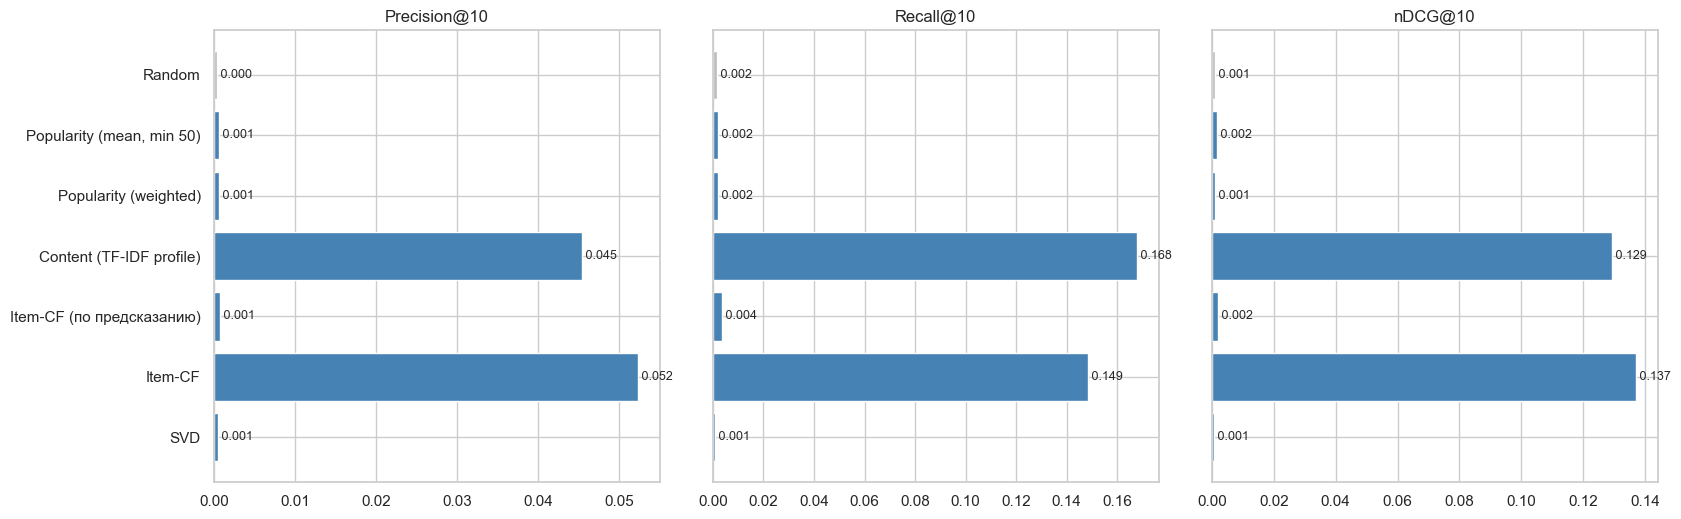

In [141]:
plot_summary(summary)

**Что видно (неожиданно!):**
- **Item-CF** и **Content** — лучшие модели: nDCG@10 около 0.13–0.14, то есть примерно в 100 раз
  лучше случайного угадывания.
- **SVD, лучший по RMSE, по метрикам ранжирования не отличается от Random!** То же самое
  с **Popularity**.
- **Item-CF по предсказанию** тоже на уровне Random. Это подтверждает вывод этапа 3:
  ранжировать по силе доказательств, а не по средней оценке.
- Coverage и Personalization объясняют провал: у Popularity и SVD покрытие каталога
  меньше 1%, а SVD выдаёт почти всем **один и тот же список** (Personalization ≈ 0.1).

### 5.5 Значимы ли различия?

У нас 3 000 пользователей, и метрика у каждого своя. Посчитаем 95%-доверительный интервал для
nDCG@10 бутстрэпом: если интервалы двух моделей не пересекаются, разница точно не случайна.

In [142]:
def bootstrap_ci(values, n_boot=1000, seed=0):
    r = np.random.default_rng(seed)
    means = [r.choice(values, len(values)).mean() for _ in range(n_boot)]
    return np.percentile(means, [2.5, 97.5])

def ci_table(per_user):
    ci = {name: bootstrap_ci(g["nDCG@10"].to_numpy()) for name, g in per_user.groupby("model", sort=False)}
    return pd.DataFrame(ci, index=["nDCG@10 low", "nDCG@10 high"]).T.round(4)

ci_table(per_user)

,nDCG@10 low,nDCG@10 high
Random,0.0004,0.0021
"Popularity (mean, min 50)",0.0006,0.0026
Popularity (weighted),0.0005,0.0018
Content (TF-IDF profile),0.1205,0.1378
Item-CF (по предсказанию),0.0011,0.0032
Item-CF,0.1278,0.1457
SVD,0.0003,0.0014


Интервалы Item-CF и Content пересекаются, поэтому их разница на этой выборке статистически
ненадёжна. Обе модели **значимо** лучше Random, Popularity и SVD.

### 5.6 Почему SVD провалился и как это исправить

**Причина: модель решает не ту задачу.**
- SVD обучался предсказывать **оценку при условии, что человек книгу прочитал**. Пропуски в
  матрице он просто игнорирует.
- Top-N метрики спрашивают другое: **какие книги человек прочитает и оценит высоко**. Решает
  здесь сам факт взаимодействия, то есть **что** человек выбирает читать.
- Предсказание SVD почти целиком определяется смещением книги $b_i$ (этап 4: выигрыш в RMSE
  дают в основном смещения). Поэтому всем рекомендуются одни и те же книги с высоким средним
  рейтингом: Calvin and Hobbes, ESV Study Bible…

**Почему не работает и Popularity.** В нашем `ratings.csv` у каждой книги около 100 оценок
(выборка обрезана, см. EDA). Поэтому «популярные» книги в тесте встречаются не чаще остальных,
и неперсонализированная выдача угадывает на уровне случайной. На реальных данных с длинным
хвостом Popularity был бы гораздо сильнее.

**Почему работают Item-CF и Content.** Они ловят то, что люди читают **вместе**: следующую
книгу серии, того же автора, тот же жанр. Именно это и предсказывается в тесте.

**Исправление: PureSVD** (Cremonesi et al., 2010) — матричное разложение для задачи Top-N:
1. берём **неявную** матрицу: 1, если пользователь оценил книгу на ≥ 4, иначе **0**. Пропуски
   здесь — информация («не выбрал читать»), а не мусор;
2. делаем обычное усечённое SVD: $M \approx U \Sigma V^\top$ с $d$ факторами (`scipy.sparse.linalg.svds`);
3. скор книг для пользователя: $\text{score}_u = m_u V V^\top$, то есть строка пользователя,
   спроецированная в пространство факторов и обратно.

Нужно много факторов: при $d$ = 20 nDCG@10 ≈ 0.01, при 200 ≈ 0.10, при 500 ≈ 0.16. Сигнал
очень «локальный» (конкретные серии и авторы), и для его описания нужно много измерений.

In [143]:
%%time
from scipy.sparse.linalg import svds

PURE_SVD_FACTORS = 500

liked_df = train_df[train_df["rating"] >= 4]
ps_user_ids = pd.Index(train_df["user_id"].unique())
ps_item_ids = pd.Index(np.sort(train_df["book_id"].unique()))
M = sp.csr_matrix(
    (np.ones(len(liked_df)), (ps_user_ids.get_indexer(liked_df["user_id"]), ps_item_ids.get_indexer(liked_df["book_id"]))),
    shape=(len(ps_user_ids), len(ps_item_ids)),
)
v0 = np.random.default_rng(42).random(min(M.shape))   # для воспроизводимости ARPACK
_, sigma, Vt = svds(M, k=PURE_SVD_FACTORS, v0=v0)
V = Vt.T                                                # (книги x факторы)
print("Матрица:", M.shape, "положительных:", M.nnz, "| V:", V.shape)


def rec_pure_svd(user_id, k):
    m_u = M[ps_user_ids.get_loc(user_id)]
    scores = np.asarray((m_u @ V) @ V.T).ravel()
    return top_k_unseen(scores, ps_item_ids.to_numpy(), seen_train[user_id], k)

Матрица: (53424, 10000) положительных: 519103 | V: (10000, 500)
CPU times: user 1min 38s, sys: 3.54 s, total: 1min 42s
Wall time: 32.6 s


In [144]:
%%time
per_user = pd.concat([per_user, run_eval({"PureSVD (implicit)": rec_pure_svd})], ignore_index=True)
summary = make_summary(per_user)
show_summary(summary)

CPU times: user 38 s, sys: 8.72 s, total: 46.7 s
Wall time: 29.7 s


,Precision@5,Recall@5,nDCG@5,Precision@10,Recall@10,nDCG@10,Coverage,Personalization,RMSE
model,,,,,,,,,
Random,0.0005,0.0014,0.0010,0.0003,0.0016,0.0011,0.9482,0.9993,—
"Popularity (mean, min 50)",0.0006,0.0011,0.0012,0.0007,0.0020,0.0015,0.0015,0.0046,—
Popularity (weighted),0.0007,0.0010,0.0008,0.0006,0.0019,0.0011,0.0016,0.0039,—
Content (TF-IDF profile),0.0639,0.1254,0.1168,0.0454,0.1680,0.1293,0.6893,0.9971,—
Item-CF (по предсказанию),0.0007,0.0019,0.0014,0.0007,0.0036,0.0021,0.9242,0.9986,—
Item-CF,0.0797,0.1230,0.1349,0.0524,0.1486,0.1372,0.8015,0.9912,—
SVD,0.0004,0.0003,0.0005,0.0005,0.0010,0.0008,0.0020,0.1085,0.8323
PureSVD (implicit),0.0951,0.1387,0.1511,0.0684,0.1930,0.1625,0.5614,0.9979,—


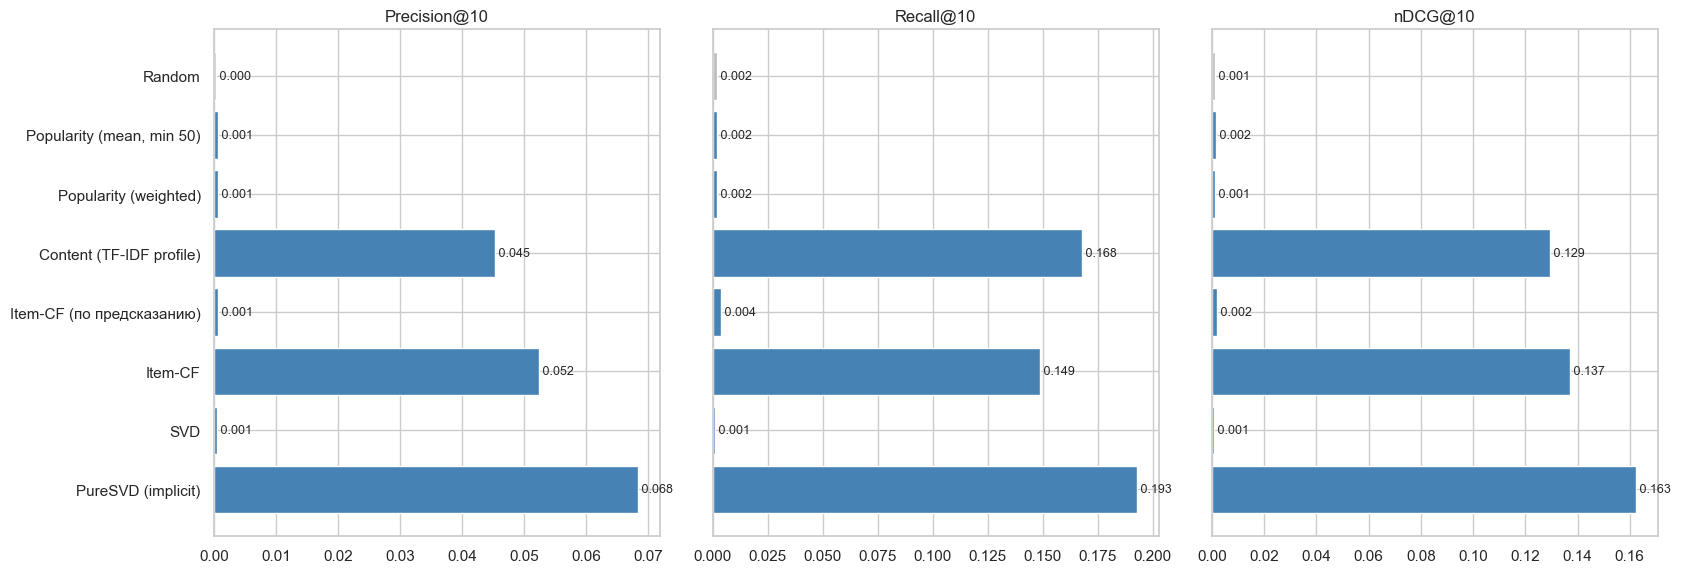

In [145]:
plot_summary(summary)

In [146]:
ci_table(per_user)

,nDCG@10 low,nDCG@10 high
Random,0.0004,0.0021
"Popularity (mean, min 50)",0.0006,0.0026
Popularity (weighted),0.0005,0.0018
Content (TF-IDF profile),0.1205,0.1378
Item-CF (по предсказанию),0.0011,0.0032
Item-CF,0.1278,0.1457
SVD,0.0003,0.0014
PureSVD (implicit),0.1526,0.1717


**PureSVD — лучшая модель по всем метрикам ранжирования**, и его интервал не пересекается с
интервалами Item-CF и Content. Главный урок этапа:

> **Низкий RMSE не означает хорошие рекомендации.** Модель надо обучать под ту задачу, на которой
> её будут оценивать. Для Top-N важны неявные сигналы (что человек выбирает читать), а не только
> точность предсказания оценки.

### 5.7 Качество в зависимости от активности пользователя

Средние метрики скрывают важное: для **холодных** пользователей (мало оценок) и для
**активных** лучше могут работать разные модели. Это ключ к гибриду на этапе 6.

In [147]:
per_user["n_train"] = per_user["user_id"].map(n_train)
per_user["segment"] = pd.cut(per_user["n_train"], bins=[0, 5, 20, 1000],
                             labels=["холодные (≤5)", "средние (6-20)", "активные (>20)"])

seg = per_user.pivot_table(index="model", columns="segment", values="nDCG@10", aggfunc="mean", observed=False)
seg = seg.loc[list(dict.fromkeys(per_user["model"]))]
print("Пользователей в сегментах:", per_user.drop_duplicates("user_id")["segment"].value_counts().to_dict())
seg.style.format("{:.4f}").background_gradient(axis=0, cmap="Greens")

Пользователей в сегментах: {'средние (6-20)': 1317, 'активные (>20)': 852, 'холодные (≤5)': 831}


segment,холодные (≤5),средние (6-20),активные (>20)
model,,,
Random,0.0000,0.0017,0.0014
"Popularity (mean, min 50)",0.0012,0.0013,0.0022
Popularity (weighted),0.0004,0.0010,0.0020
Content (TF-IDF profile),0.1242,0.1306,0.1322
Item-CF (по предсказанию),0.0008,0.0041,0.0002
Item-CF,0.0611,0.1417,0.2044
SVD,0.0003,0.0005,0.0016
PureSVD (implicit),0.0964,0.1490,0.2480


**Что видно:**
- **Холодные пользователи (≤ 5 оценок):** лучше всех **Content** (nDCG@10 ≈ 0.12). Коллаборативным
  моделям не хватает данных: Item-CF падает до ≈ 0.06, PureSVD до ≈ 0.10. Контентной модели
  достаточно одной понравившейся книги, чтобы найти продолжение серии или похожий жанр.
- **Активные пользователи (> 20 оценок):** уверенно лидирует **PureSVD** (≈ 0.25), за ним Item-CF
  (≈ 0.20). Content почти не растёт с числом оценок: он не умеет использовать «коллективный
  разум».
- Качество коллаборативных моделей **растёт с активностью**, а контентной почти не меняется.

Вывод для этапа 6: **нет одной лучшей модели для всех**. Естественный гибрид — переключаться
между моделями (или смешивать их) в зависимости от того, сколько мы знаем о пользователе.

## Этап 6. Гибридизация и выводы

### 6.1 Стратегия гибрида

Этап 5 показал, что **нет одной лучшей модели для всех**:
- для **холодных** пользователей лучше **Content**: ему хватает одной понравившейся книги;
- для **активных** лучше **PureSVD**: он использует «коллективный разум» и выигрывает с ростом
  числа оценок.

Поэтому строим **взвешенный гибрид, вес которого зависит от активности пользователя**:

$$\text{score}_{u}(i) = w_u \cdot z\big(\text{PureSVD}_u(i)\big) + (1 - w_u)\cdot z\big(\text{Content}_u(i)\big),
\qquad w_u = \frac{n_u}{n_u + \beta}$$

- $n_u$ — число оценок пользователя в train. Чем больше мы о нём знаем, тем больше доверяем
  коллаборативной модели. При $n_u = \beta$ веса равны 50/50;
- $z(\cdot)$ — стандартизация скоров по книгам-кандидатам (вычесть среднее, поделить на std).
  Без неё смешивать нельзя: у моделей разные шкалы.

Это мягкая версия **переключающего (switching) гибрида**: вместо резкого порога «≤ 5 оценок →
Content, иначе PureSVD» вес меняется плавно. Жёсткий порог проверим тоже.

**Полная стратегия холодного старта:**

| Ситуация | Что используем |
|---|---|
| Новый пользователь, ничего не знаем | Неперсонализированная выдача (популярное) |
| Новый пользователь назвал несколько любимых книг (онбординг) | Content: профиль из этих книг |
| Мало оценок | Гибрид с большим весом Content |
| Много оценок | Гибрид с большим весом PureSVD |
| **Новая книга** без оценок | Только Content: у неё есть теги и название, а коллаборативного вектора нет |

### 6.2 Честная настройка параметров

Параметр $\beta$ нельзя подбирать на тех же 3 000 пользователях, на которых считаем итоговые
метрики, иначе результат гибрида окажется завышенным (утечка). Поэтому берём **отдельные 2 000
пользователей** (`tune_users`), не пересекающихся с `eval_users`, подбираем $\beta$ на них, а
итоговое сравнение проводим на `eval_users`.

In [148]:
rest = np.setdiff1d(relevant_test.index.to_numpy(), eval_users)
tune_users = np.random.default_rng(7).choice(rest, size=2000, replace=False)
print("Пересечение tune и eval:", len(set(tune_users) & set(eval_users)))

# Скоры обеих моделей в одном порядке книг (ps_item_ids)
content_pos = id_to_row[ps_item_ids].to_numpy()
ps_items_arr = ps_item_ids.to_numpy()

def pure_svd_scores(user_id):
    m_u = M[ps_user_ids.get_loc(user_id)]
    return np.asarray((m_u @ V) @ V.T).ravel()

def zscore(x, mask):
    vals = x[~mask]
    std = vals.std()
    return (x - vals.mean()) / (std if std > 0 else 1.0)

def hybrid_scores(user_id, beta):
    seen_mask = np.isin(ps_items_arr, list(seen_train[user_id]))
    s_cf = zscore(pure_svd_scores(user_id), seen_mask)
    s_ct = zscore(content_scores(user_id)[content_pos], seen_mask)
    n = n_train.get(user_id, 0)
    if beta == "switch":                        # жёсткое переключение
        w = 0.0 if n <= 5 else 1.0
    else:
        w = n / (n + beta)
    return w * s_cf + (1 - w) * s_ct, seen_mask

Пересечение tune и eval: 0


In [149]:
%%time
BETAS = ["switch", 1, 3, 5, 10, 20, 50]
tune_rows = []
for u in tune_users:
    rel = relevant_test[u]
    seen_mask = np.isin(ps_items_arr, list(seen_train[u]))
    s_cf = zscore(pure_svd_scores(u), seen_mask)
    s_ct = zscore(content_scores(u)[content_pos], seen_mask)
    n = n_train[u]
    variants = {"PureSVD only": s_cf, "Content only": s_ct}
    for b in BETAS:
        w = (0.0 if n <= 5 else 1.0) if b == "switch" else n / (n + b)
        variants[f"beta={b}"] = w * s_cf + (1 - w) * s_ct
    for name, sc in variants.items():
        sc = sc.copy(); sc[seen_mask] = -np.inf
        top = np.argpartition(-sc, 10)[:10]
        recs = ps_items_arr[top[np.argsort(-sc[top])]].tolist()
        tune_rows.append({"variant": name, "nDCG@10": ndcg_at_k(recs, rel, 10)})

tune_res = pd.DataFrame(tune_rows).groupby("variant", sort=False)["nDCG@10"].mean().sort_values(ascending=False)
tune_res.round(4).to_frame("nDCG@10 (tune users)")

CPU times: user 29.4 s, sys: 6.24 s, total: 35.7 s
Wall time: 25.2 s


,nDCG@10 (tune users)
variant,
beta=20,0.1857
beta=50,0.1834
beta=10,0.1831
beta=5,0.1787
beta=switch,0.1776
beta=3,0.1736
beta=1,0.1677
PureSVD only,0.1631
Content only,0.1337


In [150]:
best_beta = next(v for v in tune_res.index if v.startswith("beta="))
BEST_BETA = best_beta.split("=")[1]
BEST_BETA = BEST_BETA if BEST_BETA == "switch" else float(BEST_BETA)
print("Выбранный beta:", BEST_BETA)

Выбранный beta: 20.0


### 6.3 Итоговое сравнение на `eval_users`

In [151]:
%%time
def rec_hybrid(user_id, k):
    scores, seen_mask = hybrid_scores(user_id, BEST_BETA)
    scores[seen_mask] = -np.inf
    top = np.argpartition(-scores, k)[:k]
    return ps_items_arr[top[np.argsort(-scores[top])]].tolist()

per_user = per_user[per_user["model"] != "Hybrid (PureSVD + Content)"]
new_rows = run_eval({"Hybrid (PureSVD + Content)": rec_hybrid})
new_rows["n_train"] = new_rows["user_id"].map(n_train)
new_rows["segment"] = pd.cut(new_rows["n_train"], bins=[0, 5, 20, 1000],
                             labels=["холодные (≤5)", "средние (6-20)", "активные (>20)"])
per_user = pd.concat([per_user, new_rows], ignore_index=True)

summary = make_summary(per_user)
show_summary(summary)

CPU times: user 40.3 s, sys: 8.89 s, total: 49.2 s
Wall time: 32.4 s


,Precision@5,Recall@5,nDCG@5,Precision@10,Recall@10,nDCG@10,Coverage,Personalization,RMSE
model,,,,,,,,,
Random,0.0005,0.0014,0.0010,0.0003,0.0016,0.0011,0.9482,0.9993,—
"Popularity (mean, min 50)",0.0006,0.0011,0.0012,0.0007,0.0020,0.0015,0.0015,0.0046,—
Popularity (weighted),0.0007,0.0010,0.0008,0.0006,0.0019,0.0011,0.0016,0.0039,—
Content (TF-IDF profile),0.0639,0.1254,0.1168,0.0454,0.1680,0.1293,0.6893,0.9971,—
Item-CF (по предсказанию),0.0007,0.0019,0.0014,0.0007,0.0036,0.0021,0.9242,0.9986,—
Item-CF,0.0797,0.1230,0.1349,0.0524,0.1486,0.1372,0.8015,0.9912,—
SVD,0.0004,0.0003,0.0005,0.0005,0.0010,0.0008,0.0020,0.1085,0.8323
PureSVD (implicit),0.0951,0.1387,0.1511,0.0684,0.1930,0.1625,0.5614,0.9979,—
Hybrid (PureSVD + Content),0.1010,0.1617,0.1681,0.0726,0.2219,0.1818,0.7243,0.9984,—


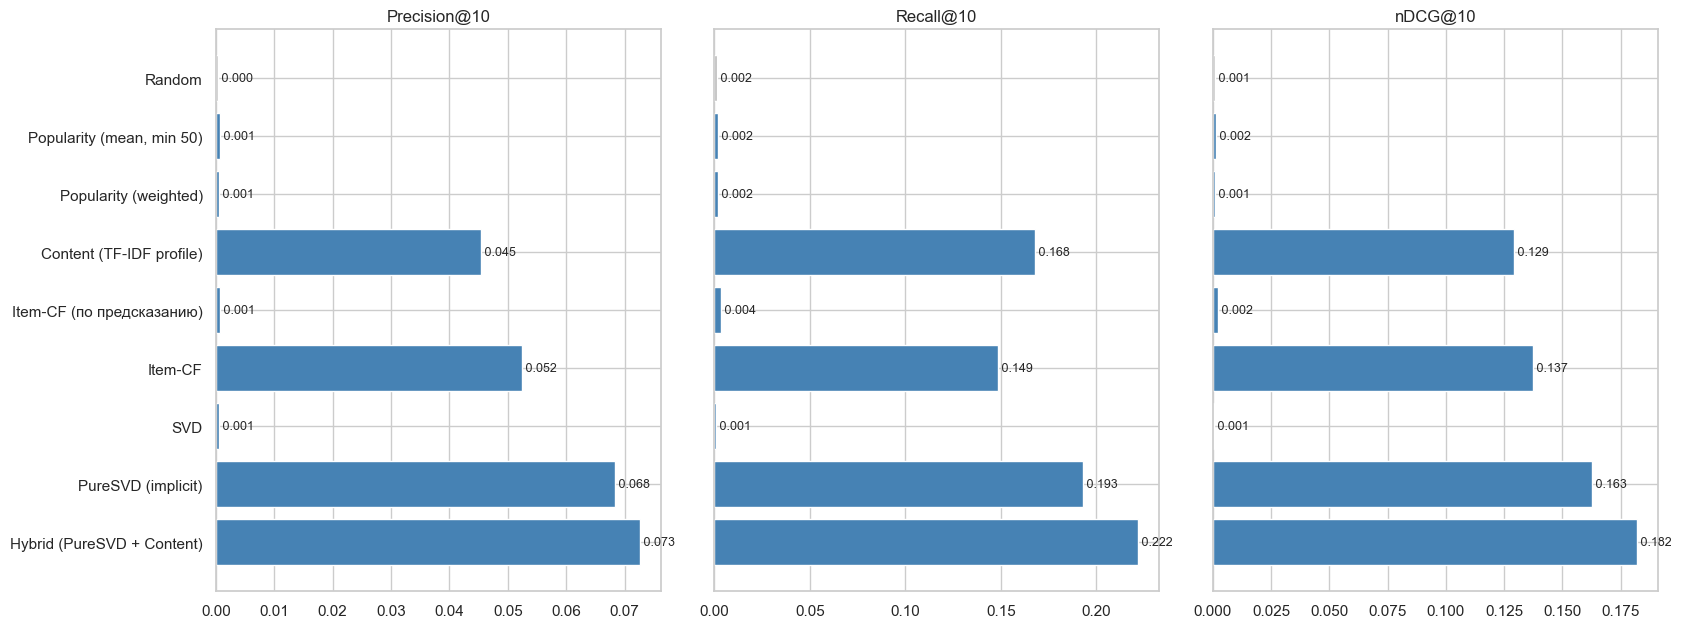

In [152]:
plot_summary(summary)

In [153]:
main_models = ["Content (TF-IDF profile)", "Item-CF", "PureSVD (implicit)", "Hybrid (PureSVD + Content)"]
seg = per_user.pivot_table(index="model", columns="segment", values="nDCG@10", aggfunc="mean", observed=False)
display(seg.loc[main_models].style.format("{:.4f}").background_gradient(axis=0, cmap="Greens"))
display(ci_table(per_user).loc[main_models])

segment,холодные (≤5),средние (6-20),активные (>20)
model,,,
Content (TF-IDF profile),0.1242,0.1306,0.1322
Item-CF,0.0611,0.1417,0.2044
PureSVD (implicit),0.0964,0.1490,0.2480
Hybrid (PureSVD + Content),0.1379,0.1649,0.2509


,nDCG@10 low,nDCG@10 high
Content (TF-IDF profile),0.1205,0.1378
Item-CF,0.1278,0.1457
PureSVD (implicit),0.1526,0.1717
Hybrid (PureSVD + Content),0.1717,0.1918


**Парный тест.** Обычные доверительные интервалы гибрида и PureSVD почти соприкасаются. Но обе
модели оценены на **одних и тех же** пользователях, поэтому точнее сравнивать **разницу метрик
у каждого пользователя** и строить бутстрэп-интервал для средней разницы.

In [154]:
def paired_diff(model_a, model_b, metric="nDCG@10"):
    a = per_user[per_user["model"] == model_a].set_index("user_id")[metric]
    b = per_user[per_user["model"] == model_b].set_index("user_id")[metric]
    d = (a - b.loc[a.index]).to_numpy()
    low, high = bootstrap_ci(d)
    return pd.Series({"mean diff": d.mean(), "CI low": low, "CI high": high,
                      "доля польз., где A лучше": (d > 0).mean(), "где хуже": (d < 0).mean()})

pd.DataFrame({
    "Hybrid − PureSVD": paired_diff("Hybrid (PureSVD + Content)", "PureSVD (implicit)"),
    "Hybrid − Content": paired_diff("Hybrid (PureSVD + Content)", "Content (TF-IDF profile)"),
    "PureSVD − Item-CF": paired_diff("PureSVD (implicit)", "Item-CF"),
}).T.round(4)

,mean diff,CI low,CI high,"доля польз., где A лучше",где хуже
Hybrid − PureSVD,0.0193,0.0146,0.0239,0.1680,0.0943
Hybrid − Content,0.0525,0.0465,0.0582,0.2813,0.0927
PureSVD − Item-CF,0.0253,0.0172,0.0340,0.2320,0.1707


**Что видно:**
- Гибрид — **лучшая модель**: nDCG@10 ≈ 0.18 против ≈ 0.16 у PureSVD и ≈ 0.13 у Content. Парный
  интервал разницы целиком выше нуля, значит, улучшение не случайно.
- Гибрид выигрывает **во всех сегментах**, но сильнее всего у **холодных** пользователей
  (≈ 0.10 → ≈ 0.14): там PureSVD не хватает данных, и Content его «подстраховывает».
- Подобранный $\beta$ = 20: у пользователя с 5 оценками вес PureSVD всего 0.2, с 20 оценками 0.5,
  со 100 оценками ≈ 0.83. Плавное смешивание оказалось лучше жёсткого переключения
  (`beta=switch`) и лучше каждой модели по отдельности: модели **дополняют** друг друга.
- Coverage гибрида (≈ 72%) выше, чем у PureSVD (≈ 56%): Content добавляет в выдачу книги из хвоста.

### 6.4 Единая функция рекомендаций с холодным стартом

Соберём всё в одну функцию, как она выглядела бы в сервисе.

In [155]:
def recommend(user_id=None, liked_books=None, N=10):
    """
    - известный пользователь          -> гибрид PureSVD + Content
    - новый, но назвал любимые книги  -> Content по этим книгам (онбординг)
    - ничего не знаем                 -> популярные книги
    """
    if user_id is not None and user_id in seen_train.index:
        book_ids, source = rec_hybrid(user_id, N), "hybrid"
    elif liked_books:
        profile = np.asarray(tfidf_matrix[id_to_row[liked_books].to_numpy()].mean(axis=0)).ravel()
        scores = np.asarray(tfidf_matrix @ profile).ravel()
        book_ids, source = top_k_unseen(scores, content_ids, set(liked_books), N), "content (onboarding)"
    else:
        book_ids, source = rec_weighted_popular(None, N), "popular"
    out = book_titles.loc[book_ids].reset_index().rename(columns={"id": "book_id"})
    out.insert(0, "source", source)
    return out

In [156]:
print("1) Известный пользователь")
display(recommend(user_id=demo_user, N=5))

print("2) Новый пользователь, на онбординге выбрал «Голодные игры» и «Дюну»")
display(recommend(liked_books=[1, 126], N=5))

print("3) Совсем новый пользователь")
display(recommend(N=5))

1) Известный пользователь


,source,book_id,title,authors
0,hybrid,3106,The Quiet American,"Graham Greene, Robert Stone"
1,hybrid,2926,The Book of Laughter and Forgetting,"Milan Kundera, Aaron Asher"
2,hybrid,7254,Homicidal Psycho Jungle Cat: A Calvin and Hobb...,Bill Watterson
3,hybrid,5207,The Days Are Just Packed: A Calvin and Hobbes ...,Bill Watterson
4,hybrid,3412,Enduring Love,Ian McEwan


2) Новый пользователь, на онбординге выбрал «Голодные игры» и «Дюну»


,source,book_id,title,authors
0,content (onboarding),20,"Mockingjay (The Hunger Games, #3)",Suzanne Collins
1,content (onboarding),507,The Hunger Games Trilogy Boxset (The Hunger Ga...,Suzanne Collins
2,content (onboarding),17,"Catching Fire (The Hunger Games, #2)",Suzanne Collins
3,content (onboarding),1262,Children of Dune (Dune Chronicles #3),Frank Herbert
4,content (onboarding),2491,Heretics of Dune (Dune Chronicles #5),Frank Herbert


3) Совсем новый пользователь


,source,book_id,title,authors
0,popular,6590,The Authoritative Calvin and Hobbes: A Calvin ...,Bill Watterson
1,popular,4483,It's a Magical World: A Calvin and Hobbes Coll...,Bill Watterson
2,popular,6920,The Indispensable Calvin and Hobbes,Bill Watterson
3,popular,3275,"Harry Potter Boxed Set, Books 1-5 (Harry Potte...","J.K. Rowling, Mary GrandPré"
4,popular,8109,"The Absolute Sandman, Volume One","Neil Gaiman, Mike Dringenberg, Chris Bachalo, ..."


Онбординг работает ожидаемо: новый пользователь сразу получает продолжения выбранных серий.
Неперсонализированная выдача (сценарий 3) — самое слабое звено: на этих данных она на уровне
Random. В реальном сервисе её стоит заменить на тренды, подборки редакции и онбординг-опрос.

#### Новая книга (холодный старт книги)

Смоделируем появление новой книги: у неё есть название и теги, но **ни одной оценки**.
Коллаборативные модели (Item-CF, SVD, PureSVD) не могут её порекомендовать: у неё нет ни
столбца в матрице оценок, ни вектора факторов. Content может: найдём пользователей, чей
контентный профиль ближе всего к книге, то есть **кому её показать первой**.

In [157]:
def users_for_new_book(new_book_id, top_n=5, candidates=eval_users[:1000]):
    book_vec = tfidf_matrix[id_to_row[new_book_id]]
    sims = []
    for u in candidates:
        liked = liked_train.get(u, [])
        if len(liked) == 0:
            continue
        profile = np.asarray(tfidf_matrix[id_to_row[liked].to_numpy()].mean(axis=0)).ravel()
        sims.append((u, float(book_vec @ profile)))
    best = sorted(sims, key=lambda x: -x[1])[:top_n]
    return pd.DataFrame([
        {"user_id": u, "similarity": round(s, 3),
         "любимые книги пользователя": "; ".join(book_titles.loc[liked_train[u][:3], "title"].str[:40])}
        for u, s in best
    ])

new_book = 20   # Mockingjay: представим, что книга только вышла
print("Новая книга:", book_titles.loc[new_book, "title"])
users_for_new_book(new_book)

Новая книга: Mockingjay (The Hunger Games, #3)


/var/folders/0v/jm0t1b9175q49hjp9kfyn44r0000gn/T/ipykernel_927/2754175123.py:9: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  sims.append((u, float(book_vec @ profile)))
/var/folders/0v/jm0t1b9175q49hjp9kfyn44r0000gn/T/ipykernel_927/2754175123.py:9: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  sims.append((u, float(book_vec @ profile)))
/var/folders/0v/jm0t1b9175q49hjp9kfyn44r0000gn/T/ipykernel_927/2754175123.py:9: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  sim

,user_id,similarity,любимые книги пользователя
0,24623,0.282,The Hunger Games Tribute Guide
1,52861,0.219,"Rise of the Elgen (Michael Vey, #2); Among the..."
2,32372,0.209,If You Find Me
3,30715,0.200,"Hunger (Gone, #2); Lies (Gone, #3); Scorpia (A..."
4,30603,0.188,"Sweet Evil (Sweet, #1); The Winner's Curse (Th..."


Модель нашла читателей фанфиков и путеводителей по «Голодным играм» и любителей YA-антиутопий.
Это и есть та аудитория, которой новую часть серии стоит показать первой. Когда у книги наберутся
оценки, её подхватят коллаборативные модели.

### 6.5 Выводы

#### Какая модель лучше и почему?

**Лучшее качество показал гибрид PureSVD + Content** (nDCG@10 ≈ 0.18, Precision@10 ≈ 0.073),
**лучшая одиночная модель — PureSVD** (nDCG@10 ≈ 0.16). PureSVD раскладывает **неявную**
матрицу «понравилось / нет» и поэтому учится тому, что действительно предсказывается в Top-N:
*какие книги человек выберет*. Гибрид добавляет к нему контентную модель там, где
коллаборативных данных мало, то есть у холодных пользователей, и выигрывает во всех сегментах.

Итоговый рейтинг по nDCG@10: Hybrid (0.18) > PureSVD (0.16) > Item-CF (0.14) ≈ Content (0.13) ≫
Popularity ≈ SVD ≈ Random (≈ 0.001).

**По RMSE лучший SVD (surprise)**, но для рекомендаций он оказался бесполезен: его
предсказание почти целиком состоит из «качества книги» $b_i$, поэтому всем выдаются одни и те же
книги с высоким средним рейтингом. Это главный урок работы: **метрика обучения должна
соответствовать задаче**. Низкий RMSE не означает хорошие рекомендации.

#### Сильные и слабые стороны моделей

| Модель | Сильные стороны | Слабые стороны |
|---|---|---|
| **Popularity** | Простота; работает для совсем новых пользователей | Нет персонализации; усиливает popularity bias; на этих данных (≈100 оценок на книгу) на уровне Random |
| **Content (TF-IDF)** | Работает для новых книг и для пользователей с 1–2 оценками; объяснимость («похожие теги») | Рекомендует «больше того же» (та же серия); зависит от качества тегов; путает совпадение слов и смысла |
| **Item-CF** | Находит связи «читают те же люди»; объяснимость («потому что вам понравилась X»); не нужны описания | Холодный старт; чувствителен к разреженности (нужен shrinkage); $O(I^2)$ памяти; плохой RMSE без учёта смещений |
| **SVD (explicit)** | Лучший RMSE; компактная модель; учитывает смещения | Оптимизирует не ту задачу: Top-N на уровне Random; шумные эмбеддинги при сильной регуляризации; холодный старт |
| **PureSVD (implicit)** | Лучшее качество Top-N; использует информацию о том, что человек *не* выбрал | Нужно много факторов (500); не предсказывает оценку; холодный старт |
| **Hybrid** | Лучшее из двух миров: Content для новичков, PureSVD для активных; закрывает холодный старт | Сложнее поддерживать (две модели); нужен подбор весов на отложенных данных |

#### Ограничения эксперимента
- В `ratings.csv` около 100 оценок на книгу (выборка обрезана), поэтому эффекты популярности здесь
  слабее, чем в реальном сервисе.
- Нет времени оценок, поэтому разбиение случайное, а не временное. Это немного оптимистично.
- Метрики считаются только по известным оценкам: книга, которую пользователь не читал, считается
  нерелевантной, хотя могла бы ему понравиться.

#### Как улучшить систему
1. **Модели для неявного фидбека:** implicit ALS, BPR, LightFM, EASE. Можно добавить `to_read.csv`
   как дополнительный сигнал интереса.
2. **Текстовые эмбеддинги** вместо TF-IDF: Word2Vec или fastText по тегам, **BERT** или
   sentence-transformers по описаниям книг. Они понимают смысл, а не совпадение слов
   (проблема «Hunger» из этапа 2).
3. **Фичи пользователей и книг:** год издания, язык, автор, жанр, демография (LightFM, факторизационные машины).
4. **Нейросетевые подходы:** two-tower модели, последовательные рекомендатели (SASRec, BERT4Rec)
   на истории чтения: «после 1-й книги серии обычно читают 2-ю».
5. **Двухэтапная архитектура:** быстрый отбор кандидатов (PureSVD, Item-CF, Content) +
   ранжирующая модель (градиентный бустинг) поверх их скоров и фичей.
6. **Разнообразие и новизна:** штраф за книги той же серии, MMR-переранжирование, контроль
   popularity bias.
7. **Онлайн-оценка:** A/B-тесты по кликам и прочтениям, временное разбиение для офлайн-оценки.